<div style="text-align:center; padding:20px 0;">
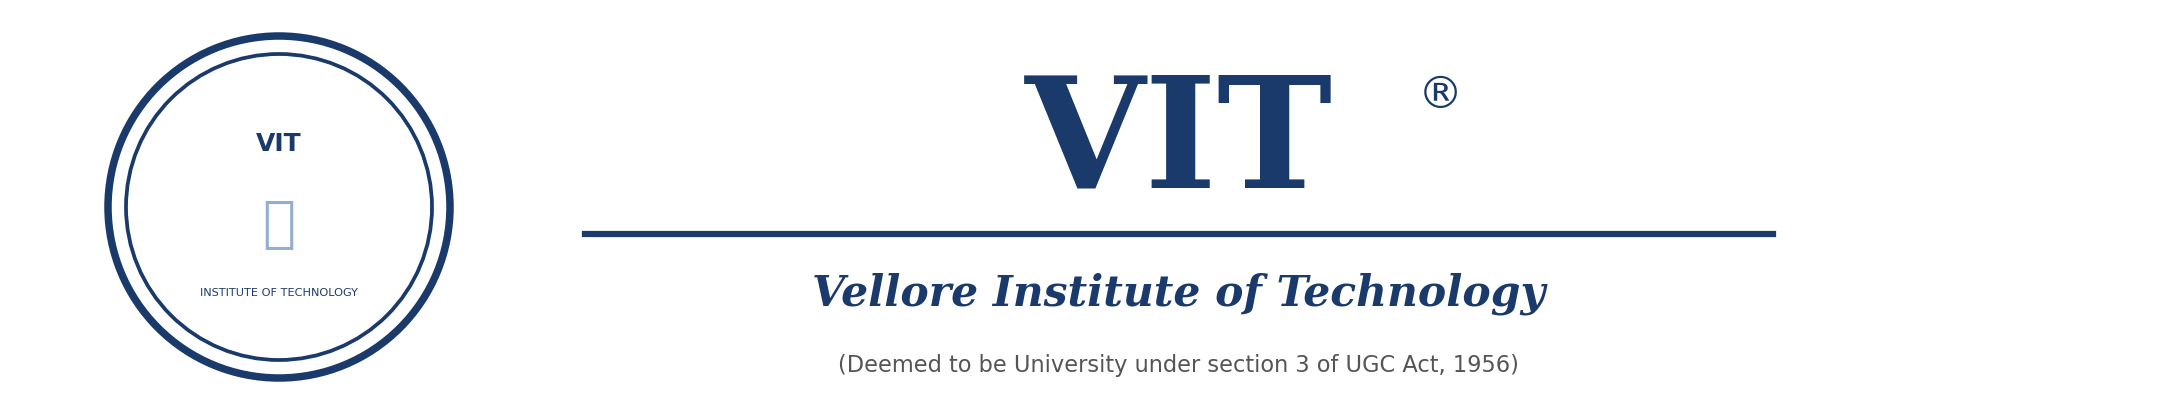
<h1 style="font-size:2.6em; font-weight:900; letter-spacing:2px; margin:8px 0;">EDA COURSE PROJECT</h1>
<hr style="border:2px solid #1a3a6b; width:60%; margin:12px auto;"/>
<p style="font-size:1.25em; margin:6px 0;"><b>Name:</b> P V S SRUTHI</p>
<p style="font-size:1.25em; margin:6px 0;"><b>Registration Number:</b> 23BDS0176</p>
<p style="font-size:1.25em; margin:6px 0;"><b>Course:</b> BCSE331P – Exploratory Data Analysis</p>
<p style="font-size:1.25em; margin:6px 0;"><b>School of Computer Science and Engineering, VIT</b></p>
<p style="font-size:1.15em; margin:6px 0;"><b>Dataset:</b> Star Classification Dataset &nbsp;|&nbsp; 240 Stars × 7 Features</p>
<hr style="border:1px solid #aaa; width:60%; margin:14px auto;"/>
</div>


## Libraries

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import skew, kurtosis, pearsonr, spearmanr
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from pandas.plotting import parallel_coordinates, scatter_matrix

plt.rcParams.update({'figure.figsize': (10, 5), 'axes.titlesize': 12})
sns.set_theme(style='whitegrid')
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 1. Dataset Loading & Preliminary Exploration

### Import Dataset

In [2]:
df = pd.read_csv('23BDS0176_EDADATASET.csv')
df.replace('?', np.nan, inplace=True)
df['Luminosity(L/Lo)'] = pd.to_numeric(df['Luminosity(L/Lo)'], errors='coerce')
star_map = {0:'Brown Dwarf',1:'Red Dwarf',2:'White Dwarf',
            3:'Main Sequence',4:'Supergiant',5:'Hypergiant'}
print(f"Shape: {df.shape[0]} rows × {df.shape[1]} columns")


Shape: 240 rows × 7 columns


### First 10 & Last 10 Records

In [3]:
print("First 10 records:"); print(df.head(10))
print("\nLast 10 records:");  print(df.tail(10))


First 10 records:
   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
0             3068          0.002400        0.1700                   16.12   
1             3042          0.000500        0.1542                   16.60   
2             2600          0.000300        0.1020                   18.70   
3             2800          0.000200        0.1600                   16.65   
4             1939          0.000138        0.1030                   20.06   
5             2840          0.000650        0.1100                   16.98   
6             2637          0.000730        0.1270                   17.22   
7             2600          0.000400        0.0960                   17.40   
8             2650          0.000690        0.1100                   17.45   
9             2700          0.000180        0.1300                   16.05   

   Star type Star color Spectral Class  
0          0        Red              M  
1          0        Red              M  


### Column Names, Data Types & Summary Statistics

In [4]:
print("Columns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nSummary Statistics:\n", df.describe(include='all'))


Columns: ['Temperature (K)', 'Luminosity(L/Lo)', 'Radius(R/Ro)', 'Absolute magnitude(Mv)', 'Star type', 'Star color', 'Spectral Class']

Data Types:
 Temperature (K)             int64
Luminosity(L/Lo)          float64
Radius(R/Ro)              float64
Absolute magnitude(Mv)    float64
Star type                   int64
Star color                 object
Spectral Class             object
dtype: object

Summary Statistics:
         Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  \
count        240.000000        239.000000    240.000000   
unique              NaN               NaN           NaN   
top                 NaN               NaN           NaN   
freq                NaN               NaN           NaN   
mean       10497.462500     106164.045156    237.157781   
std         9552.425037     179104.259253    517.155763   
min         1939.000000          0.000080      0.008400   
25%         3344.250000          0.000860      0.102750   
50%         5776.000000          0.056000    

### Missing Value Analysis

In [5]:
print("Missing values per column:\n", df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nRows containing at least one missing value:")
print(df[df.isnull().any(axis=1)])


Missing values per column:
 Temperature (K)           0
Luminosity(L/Lo)          1
Radius(R/Ro)              0
Absolute magnitude(Mv)    0
Star type                 0
Star color                3
Spectral Class            3
dtype: int64

Total missing values: 7

Rows containing at least one missing value:
     Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Absolute magnitude(Mv)  \
6               2637           0.00073         0.127                   17.22   
68              2774           0.00036         0.118                   17.39   
70              3345           0.02100         0.273                   12.30   
74              3550           0.00400         0.291                   10.89   
75              3180           0.00100         0.350                   11.76   
109            33421               NaN        67.000                   -5.79   
225            18734      224780.00000        46.000                   -7.45   

     Star type Star color Spectral Class  
6        

## 2. Data Cleaning & Preprocessing

### Handle Missing Values (Mean / Median / Mode / Forward Fill / Backward Fill / Constant)

In [6]:
df_clean = df.copy()

# Mean imputation – Luminosity
df_clean['Luminosity(L/Lo)'].fillna(df_clean['Luminosity(L/Lo)'].mean(), inplace=True)

# Median imputation – Radius
df_clean['Radius(R/Ro)'].fillna(df_clean['Radius(R/Ro)'].median(), inplace=True)

# Mode imputation – Star color
df_clean['Star color'].fillna(df_clean['Star color'].mode()[0], inplace=True)

# Forward fill then backward fill for any remaining
df_clean.ffill(inplace=True)
df_clean.bfill(inplace=True)

# Constant fill for any remaining
df_clean.fillna('Unknown', inplace=True)

print("Missing values after treatment:", df_clean.isnull().sum().sum())
print("All missing values handled.")


Missing values after treatment: 0
All missing values handled.


### Remove Duplicates

In [7]:
print(f"Duplicate rows found: {df_clean.duplicated().sum()}")
df_clean.drop_duplicates(inplace=True)
print(f"Shape after deduplication: {df_clean.shape}")


Duplicate rows found: 0
Shape after deduplication: (240, 7)


### Type Conversion & Text Normalisation

In [8]:
# Convert to appropriate types
df_clean['Star type']      = df_clean['Star type'].astype('category')
df_clean['Spectral Class'] = df_clean['Spectral Class'].astype('category')

# Standardise Star color text to title case
df_clean['Star color'] = df_clean['Star color'].str.strip().str.title().astype('category')

print("Unique Star Colors:", sorted(df_clean['Star color'].astype(str).unique()))
print("Unique Spectral Classes:", sorted(df_clean['Spectral Class'].astype(str).unique()))
print("\nUpdated dtypes:\n", df_clean.dtypes)


Unique Star Colors: ['Blue', 'Blue White', 'Blue-White', 'Orange', 'Orange-Red', 'Pale Yellow Orange', 'Red', 'White', 'White-Yellow', 'Whitish', 'Yellow-White', 'Yellowish', 'Yellowish White']
Unique Spectral Classes: ['A', 'B', 'F', 'G', 'K', 'M', 'O']

Updated dtypes:
 Temperature (K)              int64
Luminosity(L/Lo)           float64
Radius(R/Ro)               float64
Absolute magnitude(Mv)     float64
Star type                 category
Star color                category
Spectral Class            category
dtype: object


### Rename Column & Create Derived Features

In [9]:
df_clean.rename(columns={'Absolute magnitude(Mv)': 'Abs_Magnitude'}, inplace=True)

# Derived columns
df_clean['Log_Luminosity'] = np.log10(df_clean['Luminosity(L/Lo)'].astype(float) + 1e-9)
df_clean['Log_Radius']     = np.log10(df_clean['Radius(R/Ro)'].astype(float)     + 1e-9)

# Star label column for visualisation
df_clean['Star_Label'] = df_clean['Star type'].astype(int).map(star_map)

print("New columns added: Log_Luminosity, Log_Radius, Star_Label")
print(df_clean[['Temperature (K)','Log_Luminosity','Log_Radius','Abs_Magnitude','Star_Label']].head())


New columns added: Log_Luminosity, Log_Radius, Star_Label
   Temperature (K)  Log_Luminosity  Log_Radius  Abs_Magnitude   Star_Label
0             3068       -2.619789   -0.769551          16.12  Brown Dwarf
1             3042       -3.301029   -0.811916          16.60  Brown Dwarf
2             2600       -3.522877   -0.991400          18.70  Brown Dwarf
3             2800       -3.698968   -0.795880          16.65  Brown Dwarf
4             1939       -3.860118   -0.987163          20.06  Brown Dwarf


### Columns with Incorrect Data Types

In [10]:
print("Columns with potential type issues (object dtype):")
print(df_clean.select_dtypes(include='object').columns.tolist())
print("\nFinal dtypes after cleaning:")
print(df_clean.dtypes)


Columns with potential type issues (object dtype):
['Star_Label']

Final dtypes after cleaning:
Temperature (K)        int64
Luminosity(L/Lo)     float64
Radius(R/Ro)         float64
Abs_Magnitude        float64
Star type           category
Star color          category
Spectral Class      category
Log_Luminosity       float64
Log_Radius           float64
Star_Label            object
dtype: object


## 3. Descriptive Statistics

### Min, Max, Range, Variance, Standard Deviation, IQR

In [11]:
num_cols = ['Temperature (K)','Luminosity(L/Lo)','Radius(R/Ro)','Abs_Magnitude']
for col in num_cols:
    s = df_clean[col].astype(float)
    print(f"{col}:")
    print(f"  Min={s.min():.4g}  Max={s.max():.4g}  Range={s.max()-s.min():.4g}")
    print(f"  Variance={s.var():.4g}  Std Dev={s.std():.4g}")
    print(f"  IQR={s.quantile(.75)-s.quantile(.25):.4g}")
    print()


Temperature (K):
  Min=1939  Max=4e+04  Range=3.806e+04
  Variance=9.125e+07  Std Dev=9552
  IQR=1.171e+04

Luminosity(L/Lo):
  Min=8e-05  Max=8.494e+05  Range=8.494e+05
  Variance=3.194e+10  Std Dev=1.787e+05
  IQR=1.98e+05

Radius(R/Ro):
  Min=0.0084  Max=1948  Range=1948
  Variance=2.675e+05  Std Dev=517.2
  IQR=42.65

Abs_Magnitude:
  Min=-11.92  Max=20.06  Range=31.98
  Variance=110.9  Std Dev=10.53
  IQR=19.93



### Comprehensive Summary Statistics (Mean, Median, Skewness, Kurtosis)

In [12]:
rows = []
for col in num_cols:
    s = df_clean[col].astype(float)
    rows.append({'Feature':col,
                 'Mean':round(s.mean(),4), 'Median':round(s.median(),4),
                 'Min':round(s.min(),4),   'Max':round(s.max(),4),
                 'Range':round(s.max()-s.min(),4),
                 'Variance':round(s.var(),4), 'Std Dev':round(s.std(),4),
                 'IQR':round(s.quantile(.75)-s.quantile(.25),4),
                 'Skewness':round(skew(s.dropna()),4),
                 'Kurtosis':round(kurtosis(s.dropna()),4)})

stats_df = pd.DataFrame(rows).set_index('Feature')
print(stats_df.T.to_string())


Feature   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Abs_Magnitude
Mean         1.049746e+04      1.061640e+05      237.1578         4.3824
Median       5.776000e+03      7.050000e-02        0.7625         8.3130
Min          1.939000e+03      1.000000e-04        0.0084       -11.9200
Max          4.000000e+04      8.494200e+05     1948.5000        20.0600
Range        3.806100e+04      8.494200e+05     1948.4916        31.9800
Variance     9.124882e+07      3.194412e+10   267450.0836       110.9338
Std Dev      9.552425e+03      1.787292e+05      517.1558        10.5325
IQR          1.171125e+04      1.980000e+05       42.6472        19.9300
Skewness     1.313300e+00      2.085900e+00        1.9346        -0.1208
Kurtosis     8.343000e-01      4.497000e+00        2.0051        -1.6465


## 4. Univariate Analysis

### Outlier Detection – Boxplots

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
for ax, col, c in zip(axes, num_cols, ['#4C72B0','#DD8452','#55A868','#C44E52']):
    ax.boxplot(df_clean[col].astype(float), patch_artist=True,
               boxprops=dict(facecolor=c, alpha=0.7))
    ax.set_title(col, fontsize=9); ax.set_xticks([])
plt.suptitle('Boxplots – Outlier Detection', fontweight='bold')
plt.tight_layout(); plt.show()


<Figure size 1600x500 with 4 Axes>

### IQR Outlier Identification & Removal of Extreme Outliers

In [14]:
for col in ['Temperature (K)', 'Abs_Magnitude']:
    s = df_clean[col].astype(float)
    Q1, Q3 = s.quantile(.25), s.quantile(.75); IQR = Q3 - Q1
    out = df_clean[(s < Q1-1.5*IQR) | (s > Q3+1.5*IQR)]
    print(f"{col}: {len(out)} outliers  |  bounds=[{Q1-1.5*IQR:.2f}, {Q3+1.5*IQR:.2f}]")

# Remove extreme outliers (3× IQR) for clean analysis
df_no_ext = df_clean.copy()
for col in ['Temperature (K)', 'Abs_Magnitude']:
    s = df_no_ext[col].astype(float)
    Q1, Q3 = s.quantile(.25), s.quantile(.75); IQR = Q3 - Q1
    df_no_ext = df_no_ext[(s >= Q1-3*IQR) & (s <= Q3+3*IQR)]
print(f"\nShape after removing extreme outliers: {df_no_ext.shape}")


Temperature (K): 11 outliers  |  bounds=[-14222.62, 32622.38]
Abs_Magnitude: 0 outliers  |  bounds=[-36.13, 43.59]

Shape after removing extreme outliers: (240, 10)


### Histogram with Density Curve

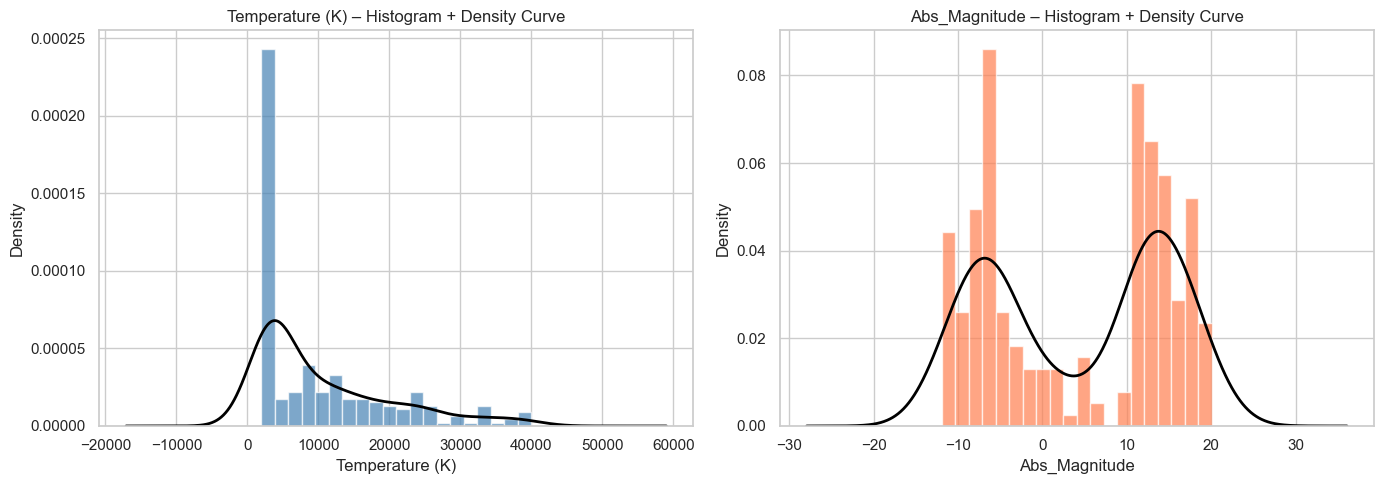

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, c in zip(axes, ['Temperature (K)', 'Abs_Magnitude'], ['steelblue','coral']):
    s = df_clean[col].astype(float)
    ax.hist(s, bins=20, density=True, color=c, edgecolor='white', alpha=0.7)
    s.plot.kde(ax=ax, color='black', linewidth=2)
    ax.set_title(f'{col} – Histogram + Density Curve')
    ax.set_xlabel(col); ax.set_ylabel('Density')
plt.tight_layout(); plt.show()


### Violin Plot – Temperature by Star Type

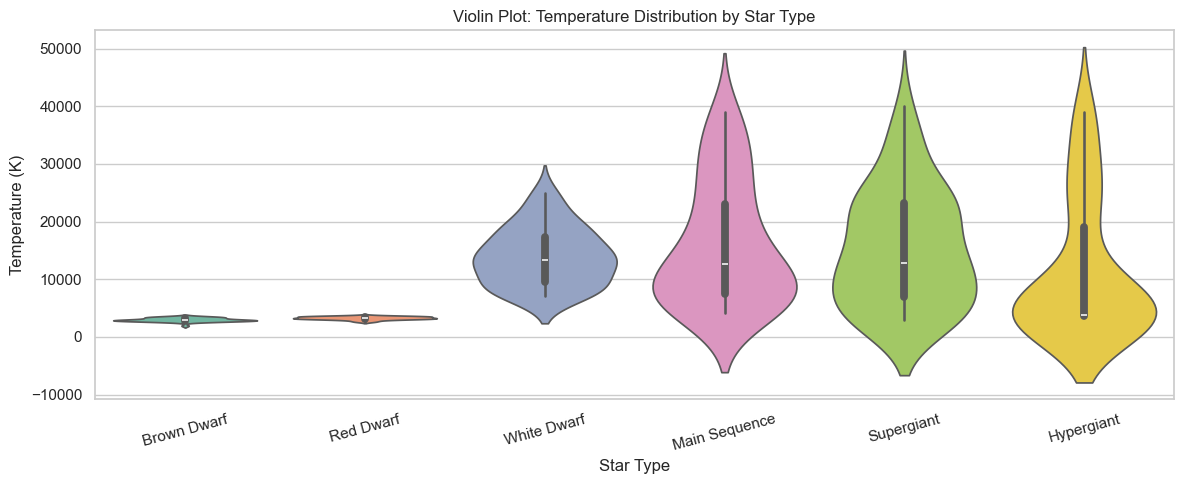

In [16]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.violinplot(data=df_clean, x='Star_Label', y='Temperature (K)', palette='Set2', ax=ax)
ax.set_title('Violin Plot: Temperature Distribution by Star Type')
ax.set_xlabel('Star Type'); ax.set_ylabel('Temperature (K)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Dot Plot – Temperature Sample

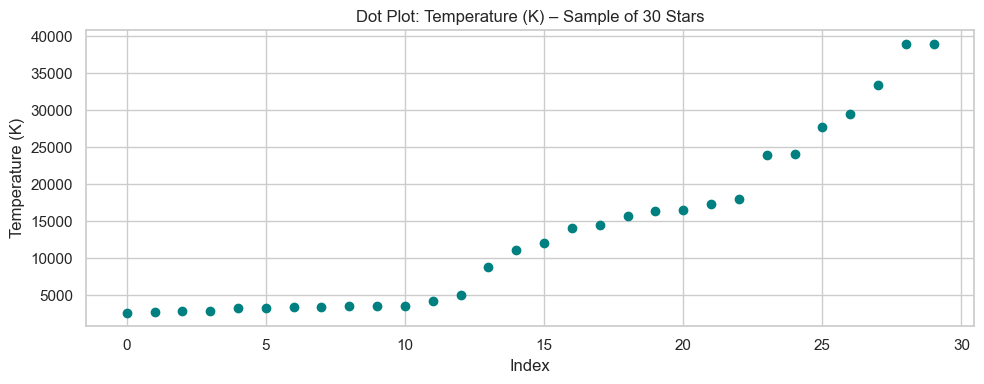

In [17]:
sample = df_clean['Temperature (K)'].astype(float).sample(30, random_state=42).sort_values()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(len(sample)), sample.values, 'o', color='teal', markersize=6)
ax.set_title('Dot Plot: Temperature (K) – Sample of 30 Stars')
ax.set_xlabel('Index'); ax.set_ylabel('Temperature (K)')
plt.tight_layout(); plt.show()


### Frequency Table for Spectral Class

In [18]:
freq = df_clean['Spectral Class'].value_counts().reset_index()
freq.columns = ['Spectral Class','Frequency']
freq['Proportion'] = (freq['Frequency']/len(df_clean)).round(4)
freq['Percentage'] = (freq['Proportion']*100).round(2)
print(freq.to_string(index=False))


Spectral Class  Frequency  Proportion  Percentage
             M        111      0.4625       46.25
             B         46      0.1917       19.17
             O         40      0.1667       16.67
             A         19      0.0792        7.92
             F         17      0.0708        7.08
             K          6      0.0250        2.50
             G          1      0.0042        0.42


### Bar Charts – Frequency, Horizontal & Percentage

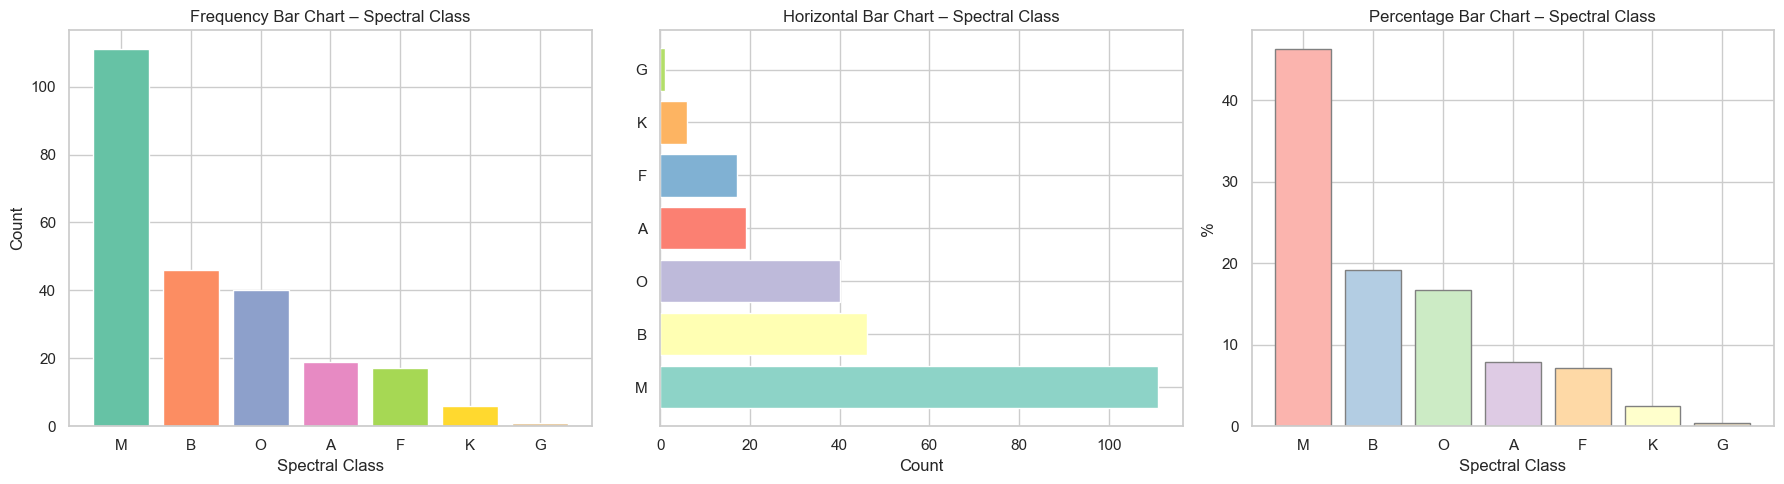

In [19]:
sc = df_clean['Spectral Class'].value_counts()
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(sc.index.astype(str), sc.values,
            color=sns.color_palette('Set2', len(sc)), edgecolor='white')
axes[0].set_title('Frequency Bar Chart – Spectral Class')
axes[0].set_xlabel('Spectral Class'); axes[0].set_ylabel('Count')

axes[1].barh(sc.index.astype(str), sc.values,
             color=sns.color_palette('Set3', len(sc)))
axes[1].set_title('Horizontal Bar Chart – Spectral Class')
axes[1].set_xlabel('Count')

pct = sc / sc.sum() * 100
axes[2].bar(pct.index.astype(str), pct.values,
            color=sns.color_palette('Pastel1', len(pct)), edgecolor='grey')
axes[2].set_title('Percentage Bar Chart – Spectral Class')
axes[2].set_xlabel('Spectral Class'); axes[2].set_ylabel('%')

plt.tight_layout(); plt.show()


### Pie Chart – Star Type Distribution

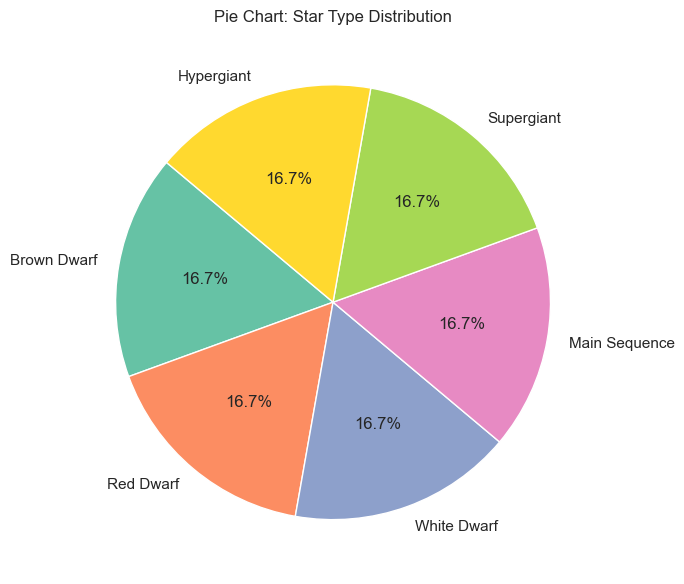

In [20]:
st_counts = df_clean['Star_Label'].value_counts()
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(st_counts.values, labels=st_counts.index, autopct='%1.1f%%',
       colors=sns.color_palette('Set2', len(st_counts)), startangle=140)
ax.set_title('Pie Chart: Star Type Distribution')
plt.tight_layout(); plt.show()


### Lollipop Chart – Spectral Class Frequency

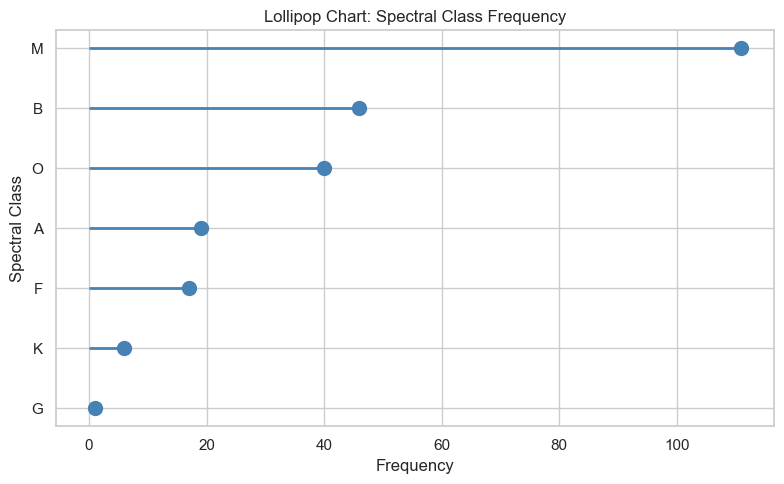

In [21]:
sc_sorted = sc.sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hlines(sc_sorted.index.astype(str), 0, sc_sorted.values, color='steelblue', lw=2)
ax.plot(sc_sorted.values, sc_sorted.index.astype(str), 'o', color='steelblue', ms=10)
ax.set_title('Lollipop Chart: Spectral Class Frequency')
ax.set_xlabel('Frequency'); ax.set_ylabel('Spectral Class')
plt.tight_layout(); plt.show()


### Dot Chart (Cleveland) – Avg Temperature by Star Type

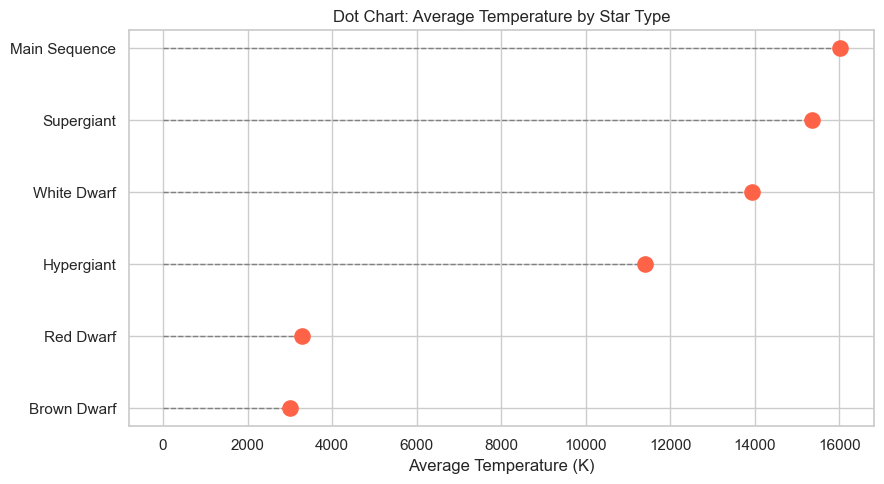

In [22]:
avg_temp = df_clean.groupby('Star_Label')['Temperature (K)'].mean().sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(avg_temp.values, avg_temp.index, color='tomato', s=120, zorder=5)
for val, name in zip(avg_temp.values, avg_temp.index):
    ax.plot([0, val], [name, name], 'grey', lw=1, ls='--')
ax.set_title('Dot Chart: Average Temperature by Star Type')
ax.set_xlabel('Average Temperature (K)')
plt.tight_layout(); plt.show()


### Density Plot – Temperature by Star Type

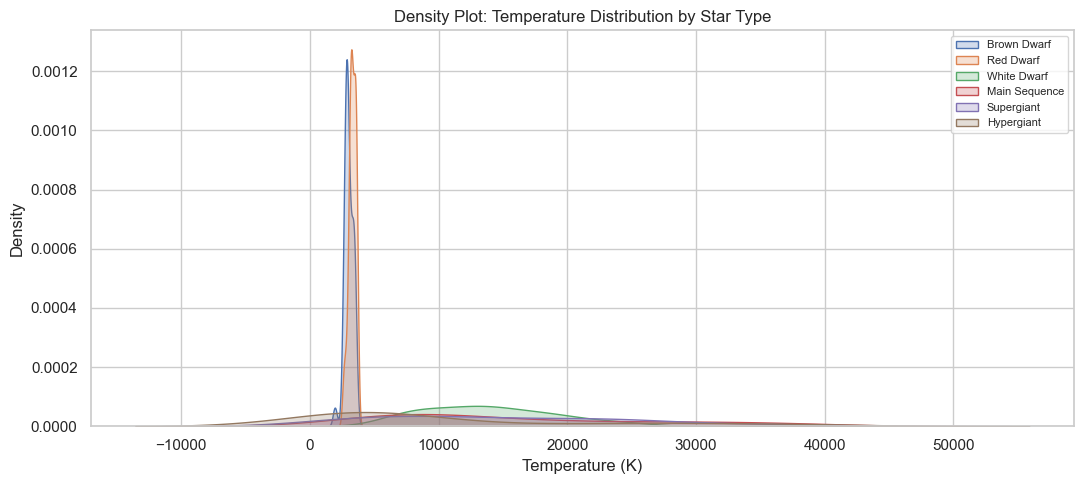

In [23]:
fig, ax = plt.subplots(figsize=(11, 5))
for label in df_clean['Star_Label'].unique():
    s = df_clean[df_clean['Star_Label']==label]['Temperature (K)'].astype(float)
    if len(s) > 2:
        sns.kdeplot(s, ax=ax, label=label, fill=True, alpha=0.25)
ax.set_title('Density Plot: Temperature Distribution by Star Type')
ax.set_xlabel('Temperature (K)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### Faceted Histograms (facet_wrap) – Temperature Across Star Types

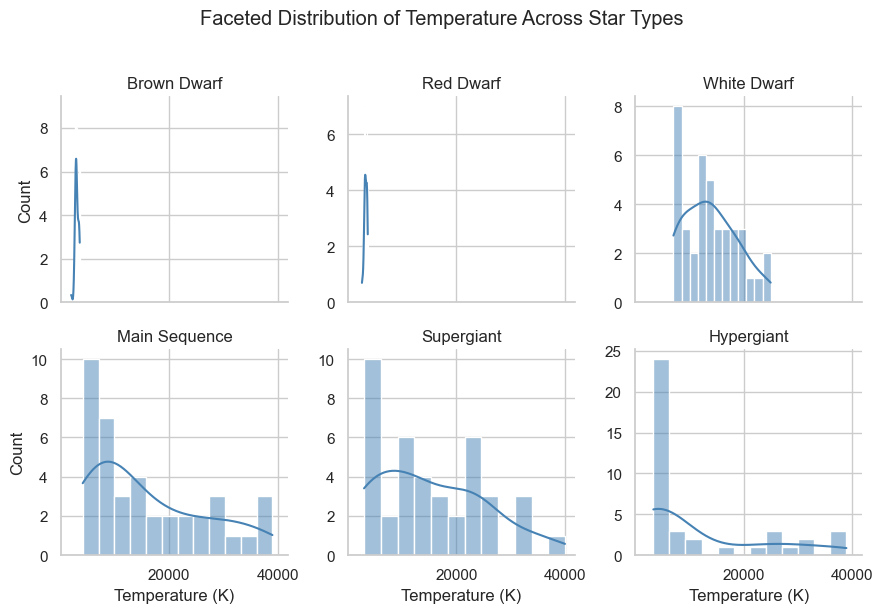

In [24]:
g = sns.FacetGrid(df_clean, col='Star_Label', col_wrap=3, height=3, sharey=False)
g.map(sns.histplot, 'Temperature (K)', kde=True, color='steelblue', bins=12)
g.set_titles(col_template='{col_name}')
g.set_axis_labels('Temperature (K)', 'Count')
g.figure.suptitle('Faceted Distribution of Temperature Across Star Types', y=1.02)
plt.tight_layout(); plt.show()


## 5. Bivariate Analysis

### Contingency Table – Star Type vs Star Color

In [25]:
def simplify_color(c):
    c = str(c).lower()
    for k in ['blue','red','white','yellow','orange']:
        if k in c: return k.title()
    return 'Other'

df_clean['Color_Group'] = df_clean['Star color'].astype(str).apply(simplify_color)
ct = pd.crosstab(df_clean['Star_Label'], df_clean['Color_Group'])
print(ct)
print("\nRow Percentages:")
print((ct.div(ct.sum(axis=1), axis=0)*100).round(1))
print("\nColumn Percentages:")
print((ct.div(ct.sum(axis=0), axis=1)*100).round(1))


Color_Group    Blue  Orange  Other  Red  White  Yellow
Star_Label                                            
Brown Dwarf       0       0      0   40      0       0
Hypergiant       13       2      0   23      2       0
Main Sequence    26       0      2    1      8       3
Red Dwarf         0       0      0   40      0       0
Supergiant       30       0      0   10      0       0
White Dwarf      27       0      0    0     12       1

Row Percentages:
Color_Group    Blue  Orange  Other    Red  White  Yellow
Star_Label                                              
Brown Dwarf     0.0     0.0    0.0  100.0    0.0     0.0
Hypergiant     32.5     5.0    0.0   57.5    5.0     0.0
Main Sequence  65.0     0.0    5.0    2.5   20.0     7.5
Red Dwarf       0.0     0.0    0.0  100.0    0.0     0.0
Supergiant     75.0     0.0    0.0   25.0    0.0     0.0
White Dwarf    67.5     0.0    0.0    0.0   30.0     2.5

Column Percentages:
Color_Group    Blue  Orange  Other   Red  White  Yellow
Star_Labe

### Stacked Bar Plot – Star Type vs Color

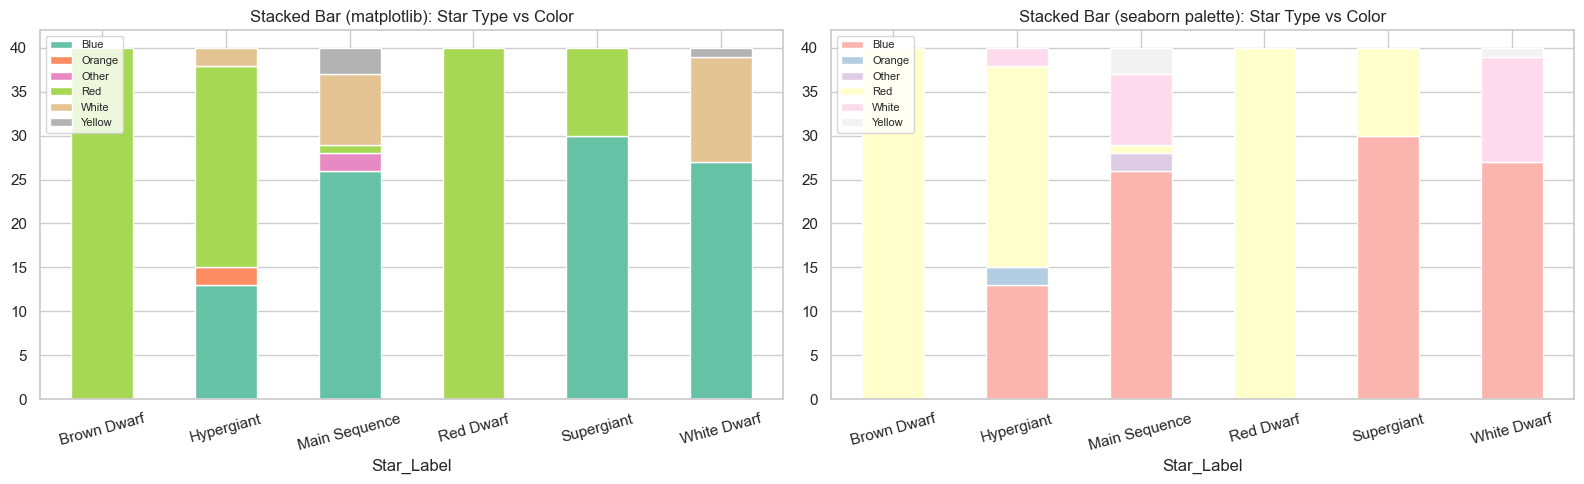

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ct.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2')
axes[0].set_title('Stacked Bar (matplotlib): Star Type vs Color')
axes[0].tick_params(axis='x', rotation=15); axes[0].legend(fontsize=8)

ct.plot(kind='bar', stacked=True, ax=axes[1], colormap='Pastel1')
axes[1].set_title('Stacked Bar (seaborn palette): Star Type vs Color')
axes[1].tick_params(axis='x', rotation=15); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


### Grouped (Side-by-Side) Bar Plot

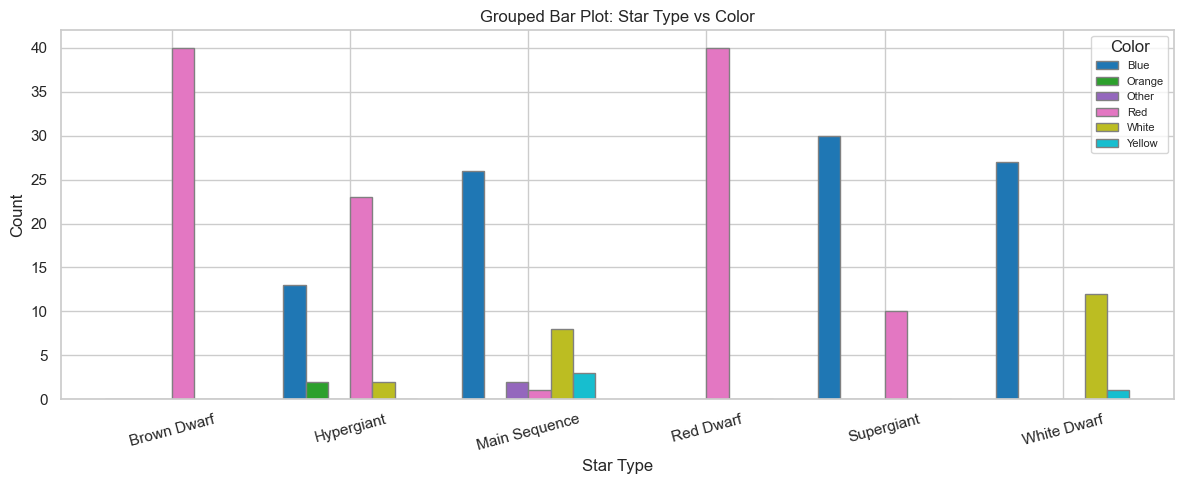

In [27]:
ct.plot(kind='bar', stacked=False, figsize=(12, 5),
        colormap='tab10', edgecolor='grey', width=0.75)
plt.title('Grouped Bar Plot: Star Type vs Color')
plt.xlabel('Star Type'); plt.ylabel('Count')
plt.xticks(rotation=15); plt.legend(title='Color', fontsize=8)
plt.tight_layout(); plt.show()


### Scatter Plot – Temperature vs Log Luminosity

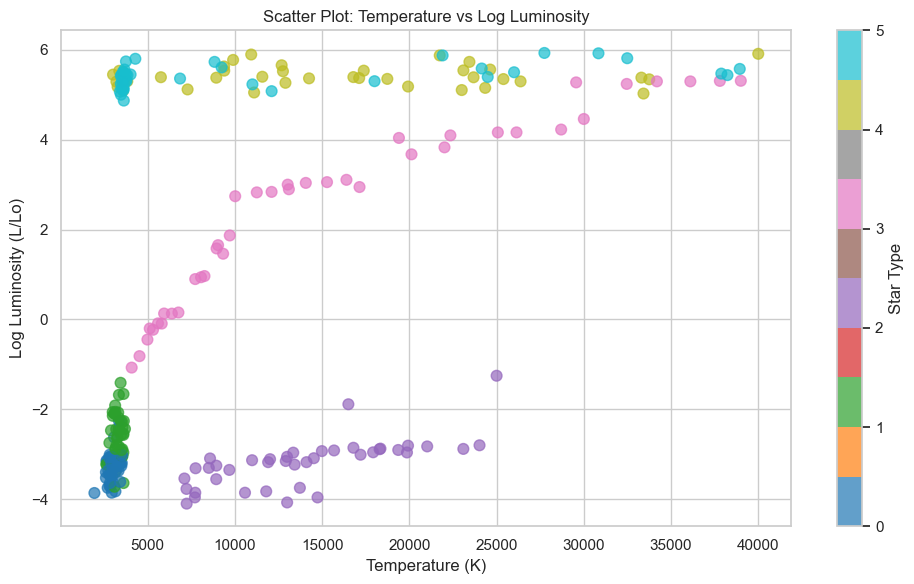

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df_clean['Temperature (K)'], df_clean['Log_Luminosity'],
                c=df_clean['Star type'].astype(int), cmap='tab10', alpha=0.7, s=60)
plt.colorbar(sc, ax=ax, label='Star Type')
ax.set_title('Scatter Plot: Temperature vs Log Luminosity')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity (L/Lo)')
plt.tight_layout(); plt.show()


### Line Plot – Avg Temperature & Log Luminosity by Star Type

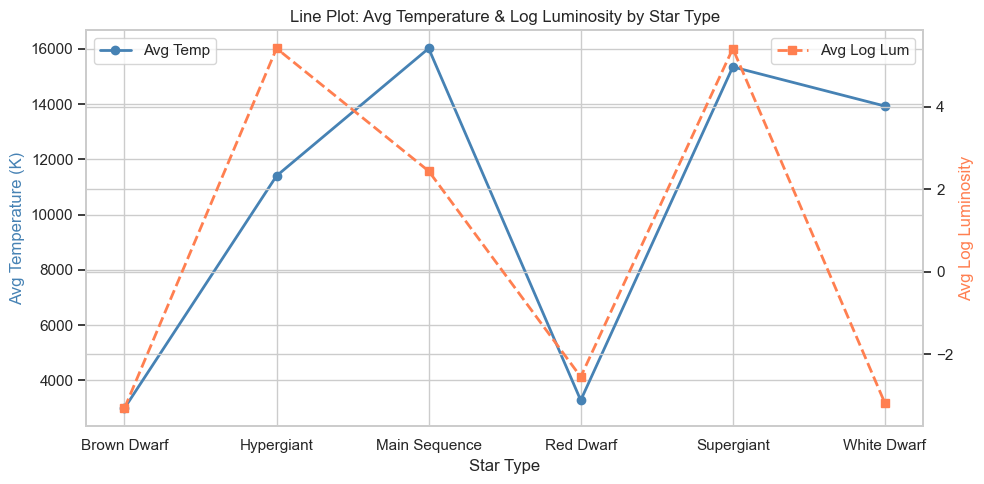

In [29]:
avg = df_clean.groupby('Star_Label').agg(
    Avg_Temp=('Temperature (K)','mean'),
    Avg_LogLum=('Log_Luminosity','mean')).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(avg['Star_Label'], avg['Avg_Temp'], 'o-', color='steelblue', lw=2, label='Avg Temp')
ax2 = ax.twinx()
ax2.plot(avg['Star_Label'], avg['Avg_LogLum'], 's--', color='coral', lw=2, label='Avg Log Lum')
ax.set_title('Line Plot: Avg Temperature & Log Luminosity by Star Type')
ax.set_xlabel('Star Type'); ax.set_ylabel('Avg Temperature (K)', color='steelblue')
ax2.set_ylabel('Avg Log Luminosity', color='coral')
plt.xticks(rotation=15); ax.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()


### Correlation Heatmap

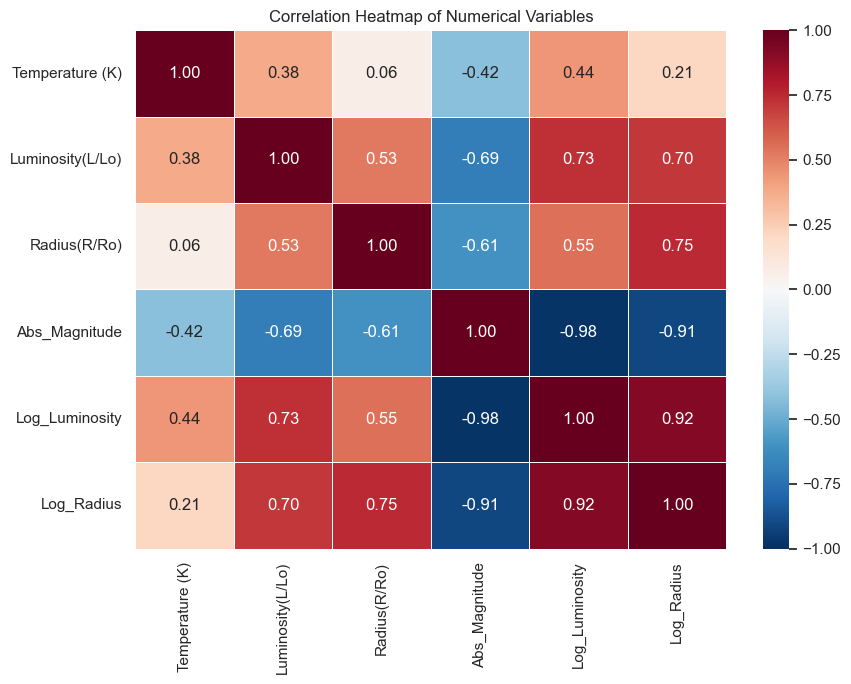

In [30]:
num_cols_h = ['Temperature (K)','Luminosity(L/Lo)','Radius(R/Ro)',
              'Abs_Magnitude','Log_Luminosity','Log_Radius']
corr = df_clean[num_cols_h].astype(float).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation Heatmap of Numerical Variables')
plt.tight_layout(); plt.show()


### Bar Chart – Mean Temperature per Spectral Class

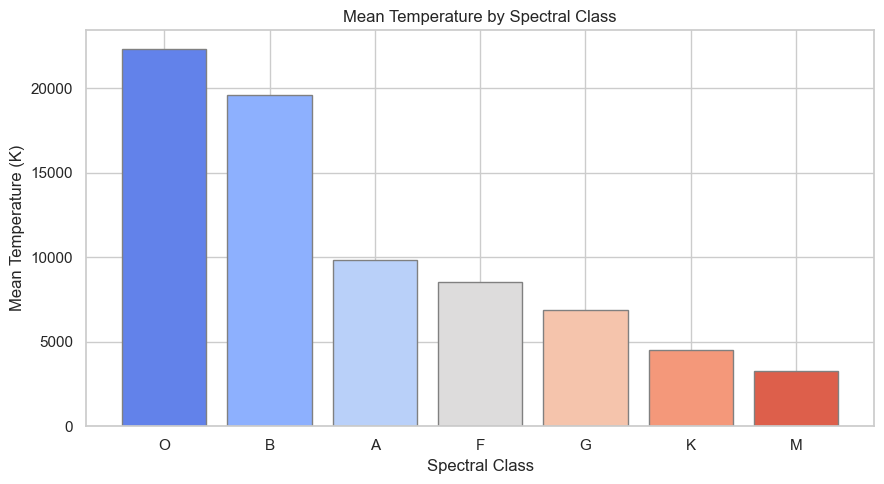

In [31]:
bar_data = df_clean.groupby('Spectral Class', observed=True)['Temperature (K)'].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(bar_data.index.astype(str), bar_data.values,
       color=sns.color_palette('coolwarm', len(bar_data)), edgecolor='grey')
ax.set_title('Mean Temperature by Spectral Class')
ax.set_xlabel('Spectral Class'); ax.set_ylabel('Mean Temperature (K)')
plt.tight_layout(); plt.show()


### Density Plot by Category – Temperature Across Star Types

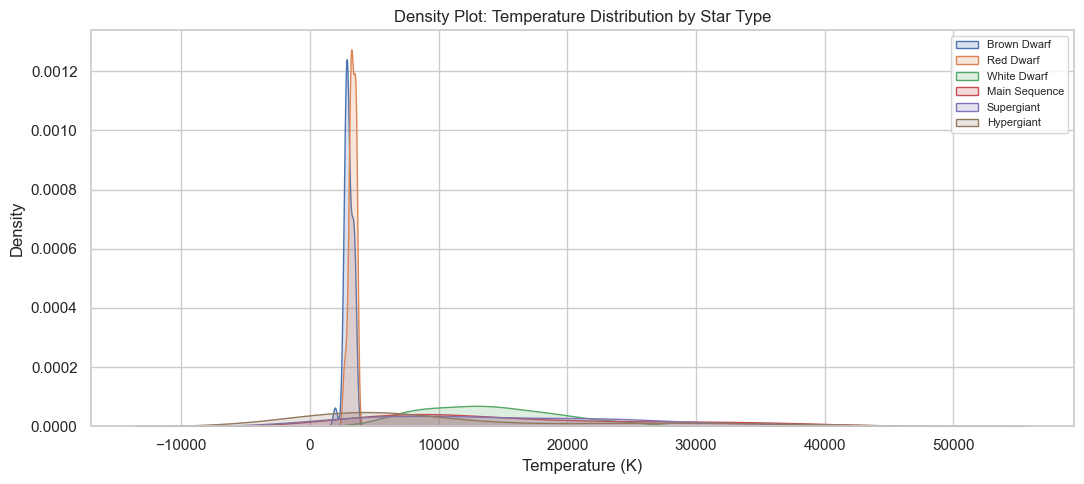

In [32]:
fig, ax = plt.subplots(figsize=(11, 5))
for label in df_clean['Star_Label'].unique():
    s = df_clean[df_clean['Star_Label']==label]['Temperature (K)'].astype(float)
    sns.kdeplot(s, ax=ax, label=label, fill=True, alpha=0.2)
ax.set_title('Density Plot: Temperature Distribution by Star Type')
ax.set_xlabel('Temperature (K)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


### Box Plot – Temperature by Star Type

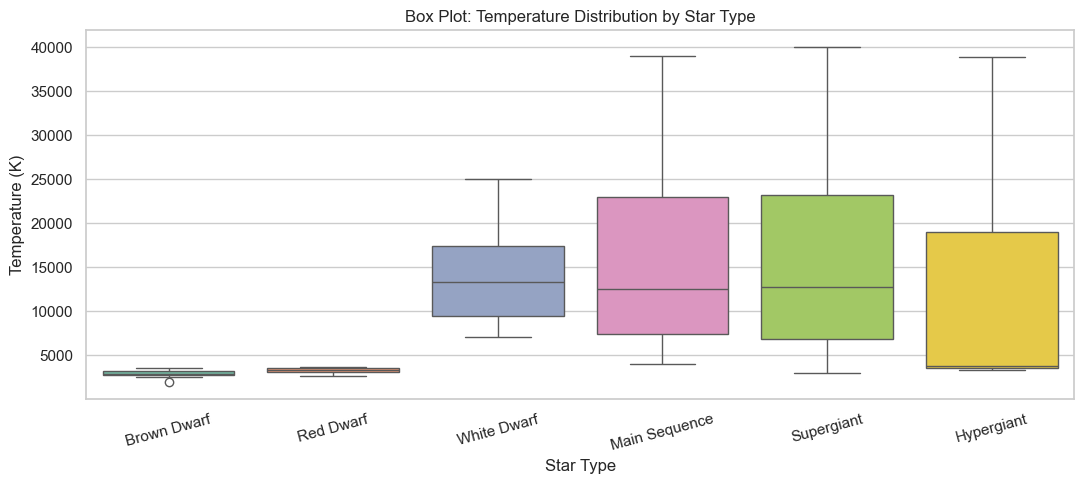

In [33]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_clean, x='Star_Label', y='Temperature (K)', palette='Set2', ax=ax)
ax.set_title('Box Plot: Temperature Distribution by Star Type')
ax.set_xlabel('Star Type'); ax.set_ylabel('Temperature (K)')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Violin Plot – Absolute Magnitude by Star Type

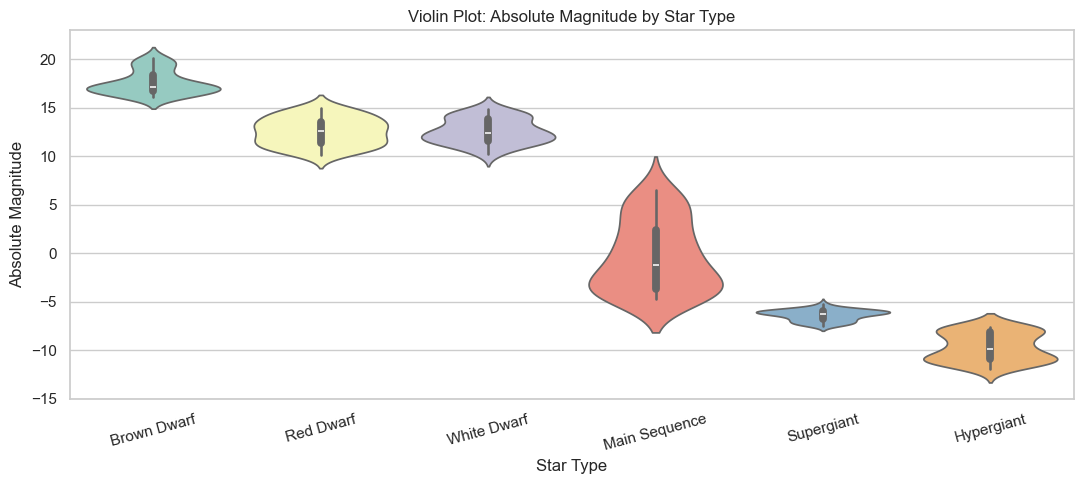

In [34]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.violinplot(data=df_clean, x='Star_Label', y='Abs_Magnitude', palette='Set3', ax=ax)
ax.set_title('Violin Plot: Absolute Magnitude by Star Type')
ax.set_xlabel('Star Type'); ax.set_ylabel('Absolute Magnitude')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Combined Violin + Box Plot

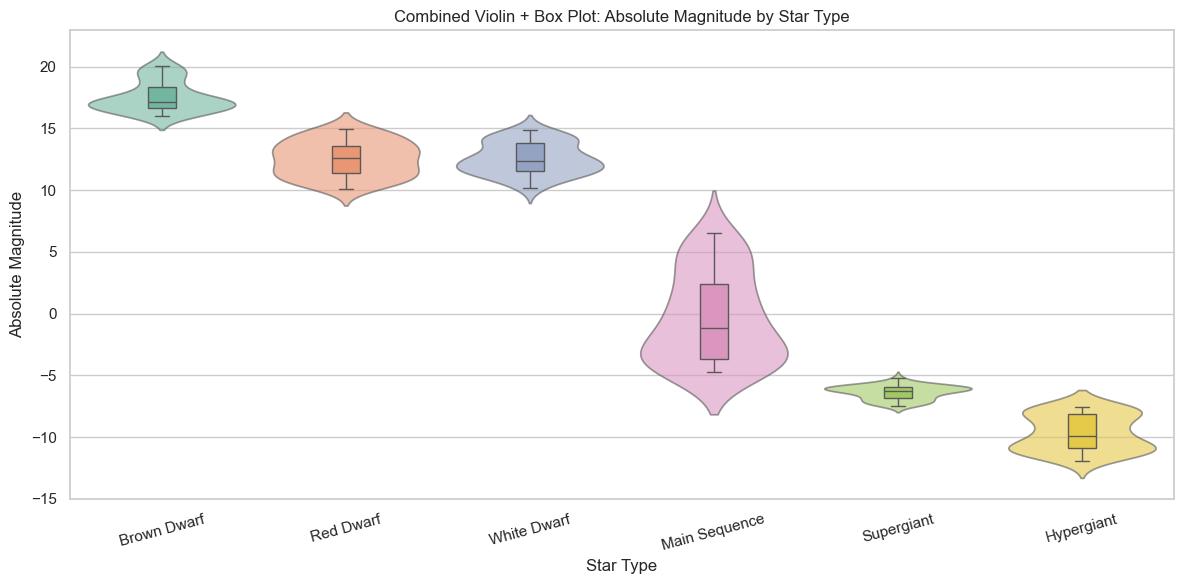

In [35]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.violinplot(data=df_clean, x='Star_Label', y='Abs_Magnitude',
               palette='Set2', inner=None, ax=ax, alpha=0.6)
sns.boxplot(data=df_clean, x='Star_Label', y='Abs_Magnitude',
            width=0.15, palette='Set2', ax=ax, zorder=2)
ax.set_title('Combined Violin + Box Plot: Absolute Magnitude by Star Type')
ax.set_xlabel('Star Type'); ax.set_ylabel('Absolute Magnitude')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()


### Correlogram – Scatter Plot Matrix

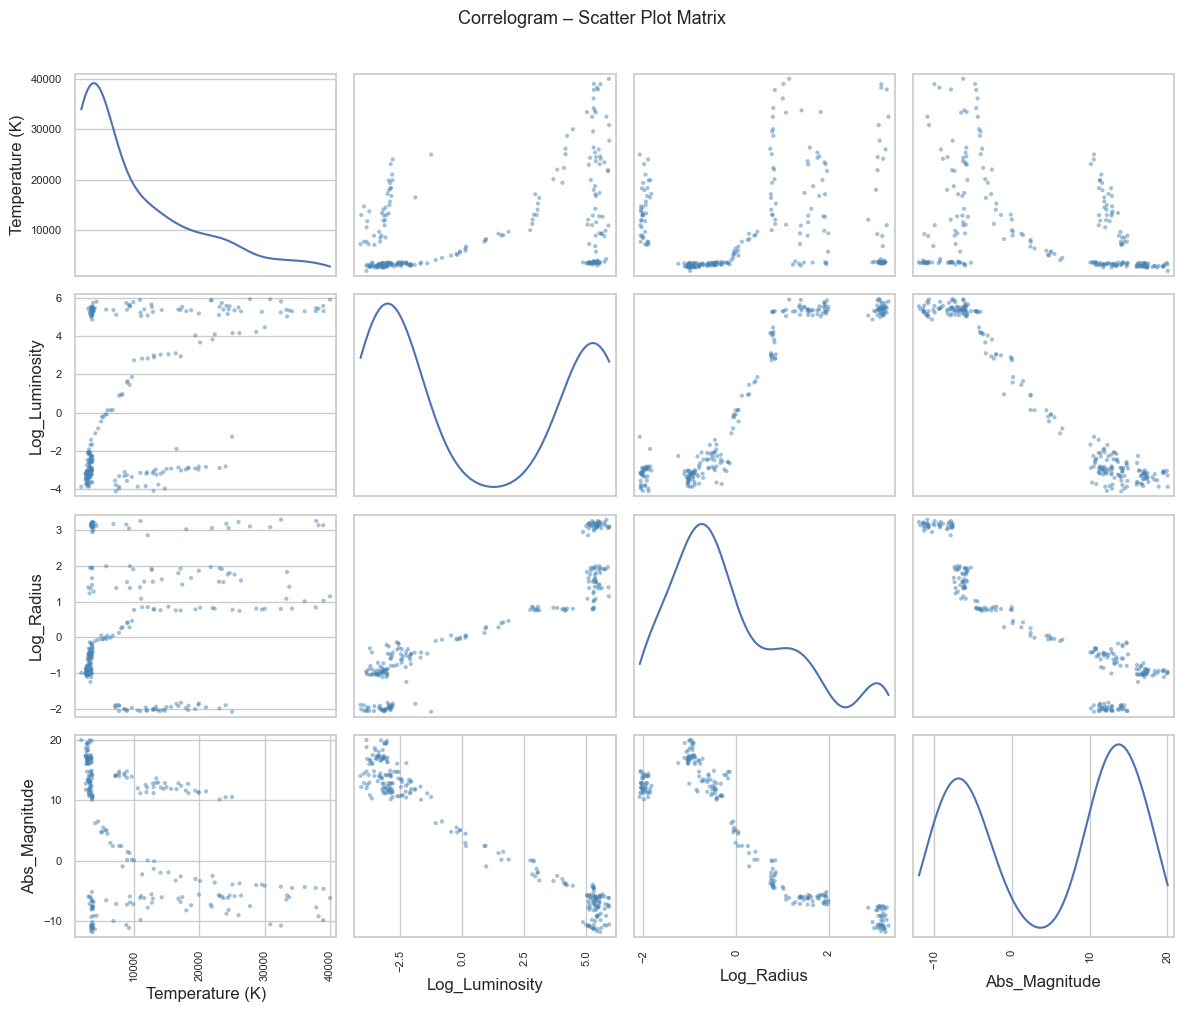

In [36]:
cols4 = ['Temperature (K)','Log_Luminosity','Log_Radius','Abs_Magnitude']
scatter_matrix(df_clean[cols4].astype(float), diagonal='kde', alpha=0.5,
               figsize=(12, 10), color='steelblue')
plt.suptitle('Correlogram – Scatter Plot Matrix', y=1.01, fontsize=13)
plt.tight_layout(); plt.show()


## 6. Multivariate Analysis

### 3-Variable Scatter (X, Y, Color)

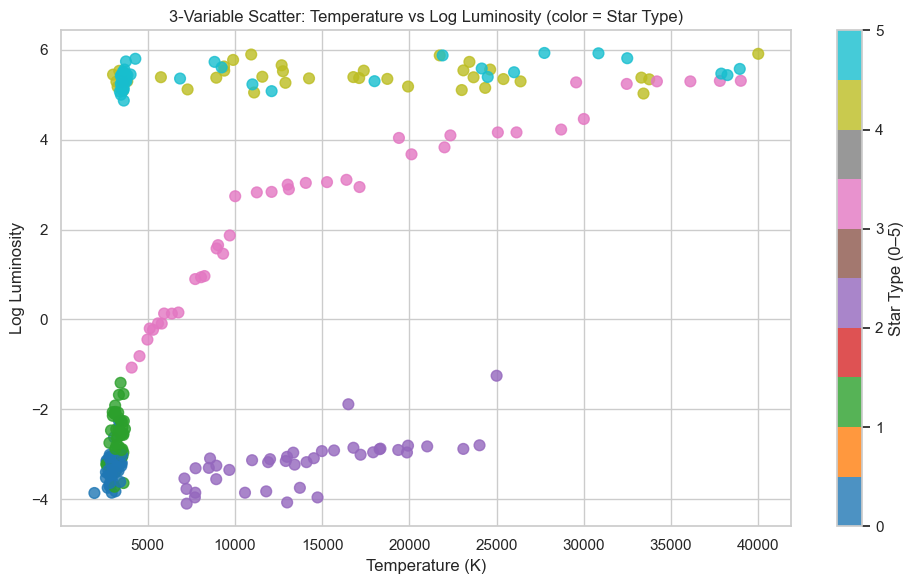

In [37]:
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df_clean['Temperature (K)'], df_clean['Log_Luminosity'],
                c=df_clean['Star type'].astype(int), cmap='tab10', alpha=0.8, s=60)
plt.colorbar(sc, ax=ax, label='Star Type (0–5)')
ax.set_title('3-Variable Scatter: Temperature vs Log Luminosity (color = Star Type)')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity')
plt.tight_layout(); plt.show()


### 4-Variable Scatter (X, Y, Color, Shape)

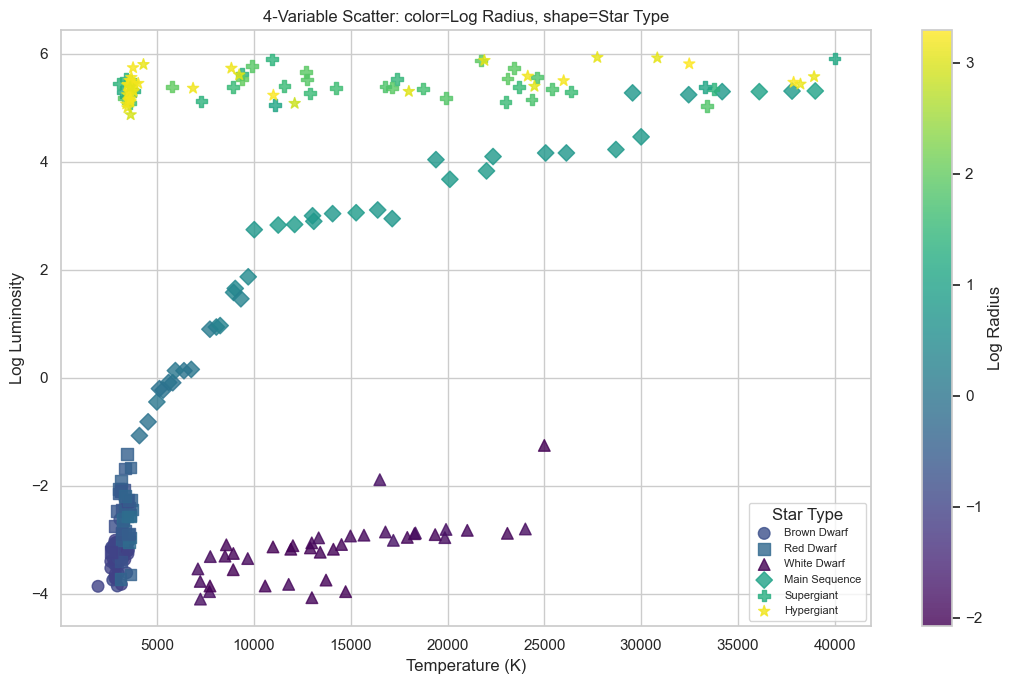

In [38]:
markers = {0:'o',1:'s',2:'^',3:'D',4:'P',5:'*'}
fig, ax = plt.subplots(figsize=(11, 7))
for stype, label in star_map.items():
    sub = df_clean[df_clean['Star type'].astype(int)==stype]
    sc = ax.scatter(sub['Temperature (K)'], sub['Log_Luminosity'],
                    c=sub['Log_Radius'], cmap='viridis', marker=markers[stype],
                    s=70, alpha=0.8, label=label,
                    vmin=df_clean['Log_Radius'].min(), vmax=df_clean['Log_Radius'].max())
plt.colorbar(sc, ax=ax, label='Log Radius')
ax.legend(title='Star Type', fontsize=8)
ax.set_title('4-Variable Scatter: color=Log Radius, shape=Star Type')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity')
plt.tight_layout(); plt.show()


### 4-Variable Scatter (X, Y, Color, Point Size)

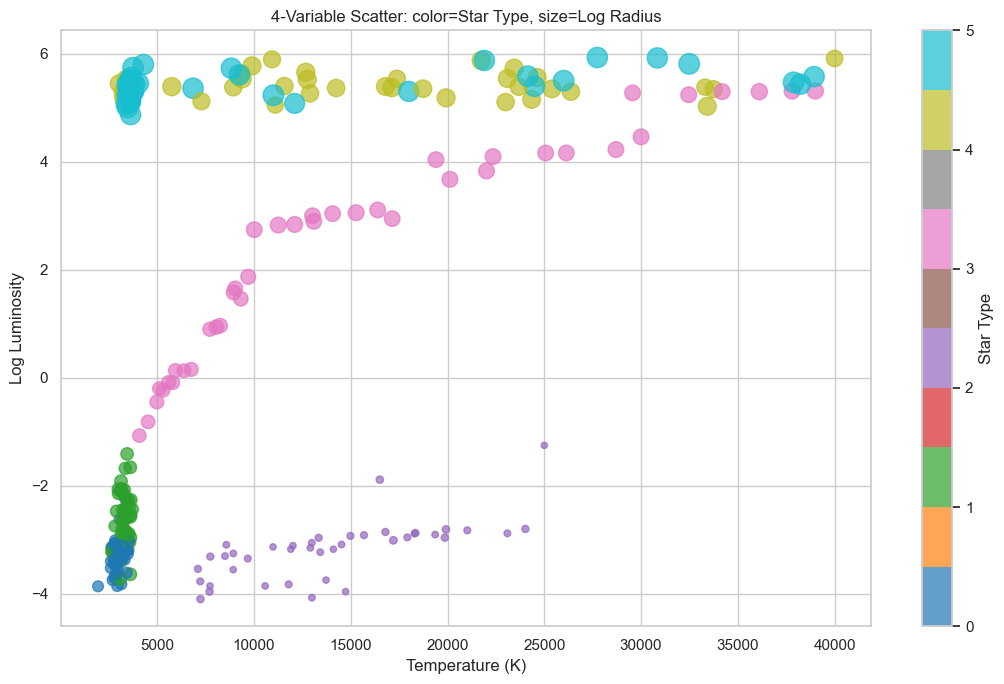

In [39]:
r_norm = (df_clean['Log_Radius'] - df_clean['Log_Radius'].min()) /          (df_clean['Log_Radius'].max() - df_clean['Log_Radius'].min())
fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(df_clean['Temperature (K)'], df_clean['Log_Luminosity'],
                c=df_clean['Star type'].astype(int), cmap='tab10',
                s=20 + 200*r_norm, alpha=0.7)
plt.colorbar(sc, ax=ax, label='Star Type')
ax.set_title('4-Variable Scatter: color=Star Type, size=Log Radius')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity')
plt.tight_layout(); plt.show()


### Bubble Plot – Temperature vs Absolute Magnitude (size = Log Radius)

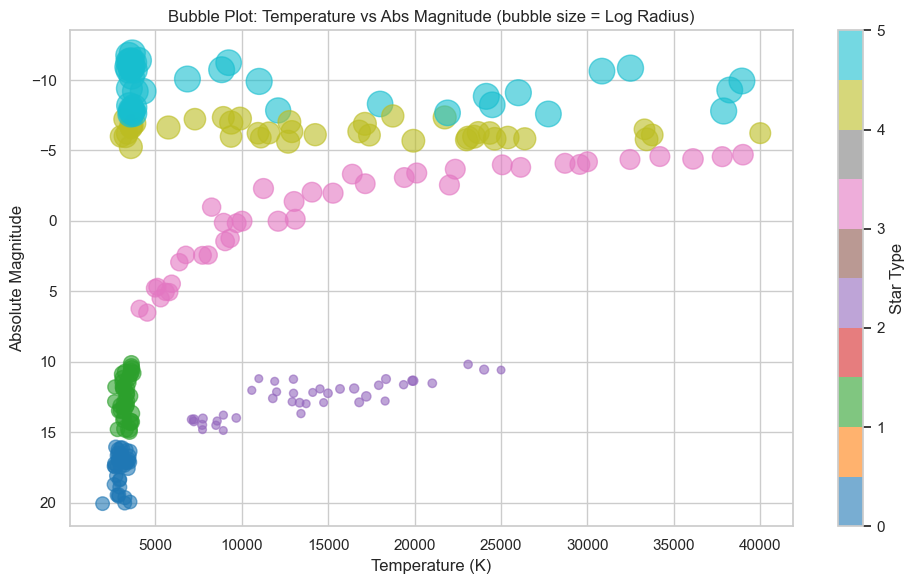

In [40]:
bsize = (df_clean['Log_Radius'] - df_clean['Log_Radius'].min() + 0.5) * 60
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(df_clean['Temperature (K)'], df_clean['Abs_Magnitude'],
                s=bsize, c=df_clean['Star type'].astype(int), cmap='tab10', alpha=0.6)
plt.colorbar(sc, ax=ax, label='Star Type')
ax.set_title('Bubble Plot: Temperature vs Abs Magnitude (bubble size = Log Radius)')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Absolute Magnitude')
ax.invert_yaxis(); plt.tight_layout(); plt.show()


### Facet Wrap – Scatter by Star Type

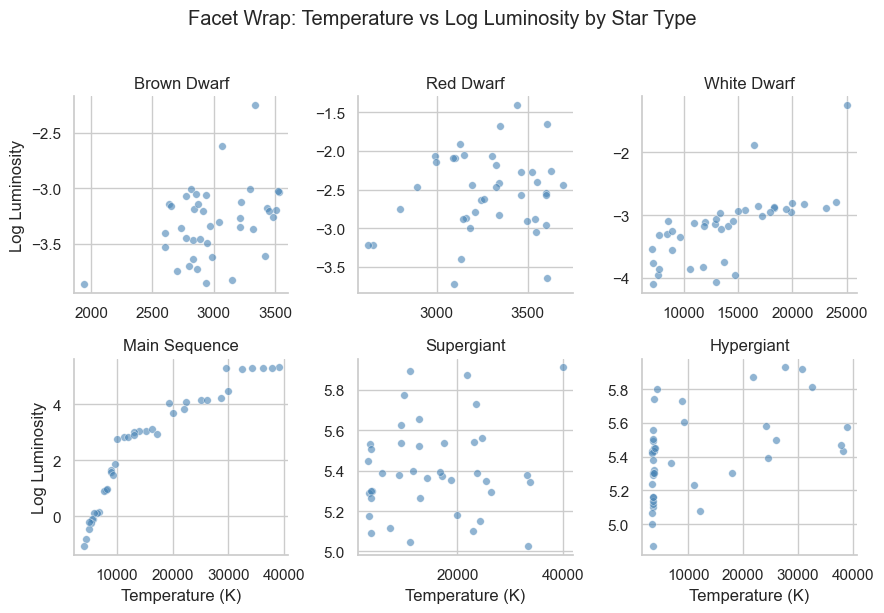

In [41]:
g = sns.FacetGrid(df_clean, col='Star_Label', col_wrap=3, height=3,
                  sharex=False, sharey=False)
g.map_dataframe(sns.scatterplot, x='Temperature (K)', y='Log_Luminosity',
                color='steelblue', alpha=0.6, s=30)
g.set_titles(col_template='{col_name}')
g.set_axis_labels('Temperature (K)', 'Log Luminosity')
g.figure.suptitle('Facet Wrap: Temperature vs Log Luminosity by Star Type', y=1.02)
plt.tight_layout(); plt.show()


### Facet Grid – Spectral Class × Color Group

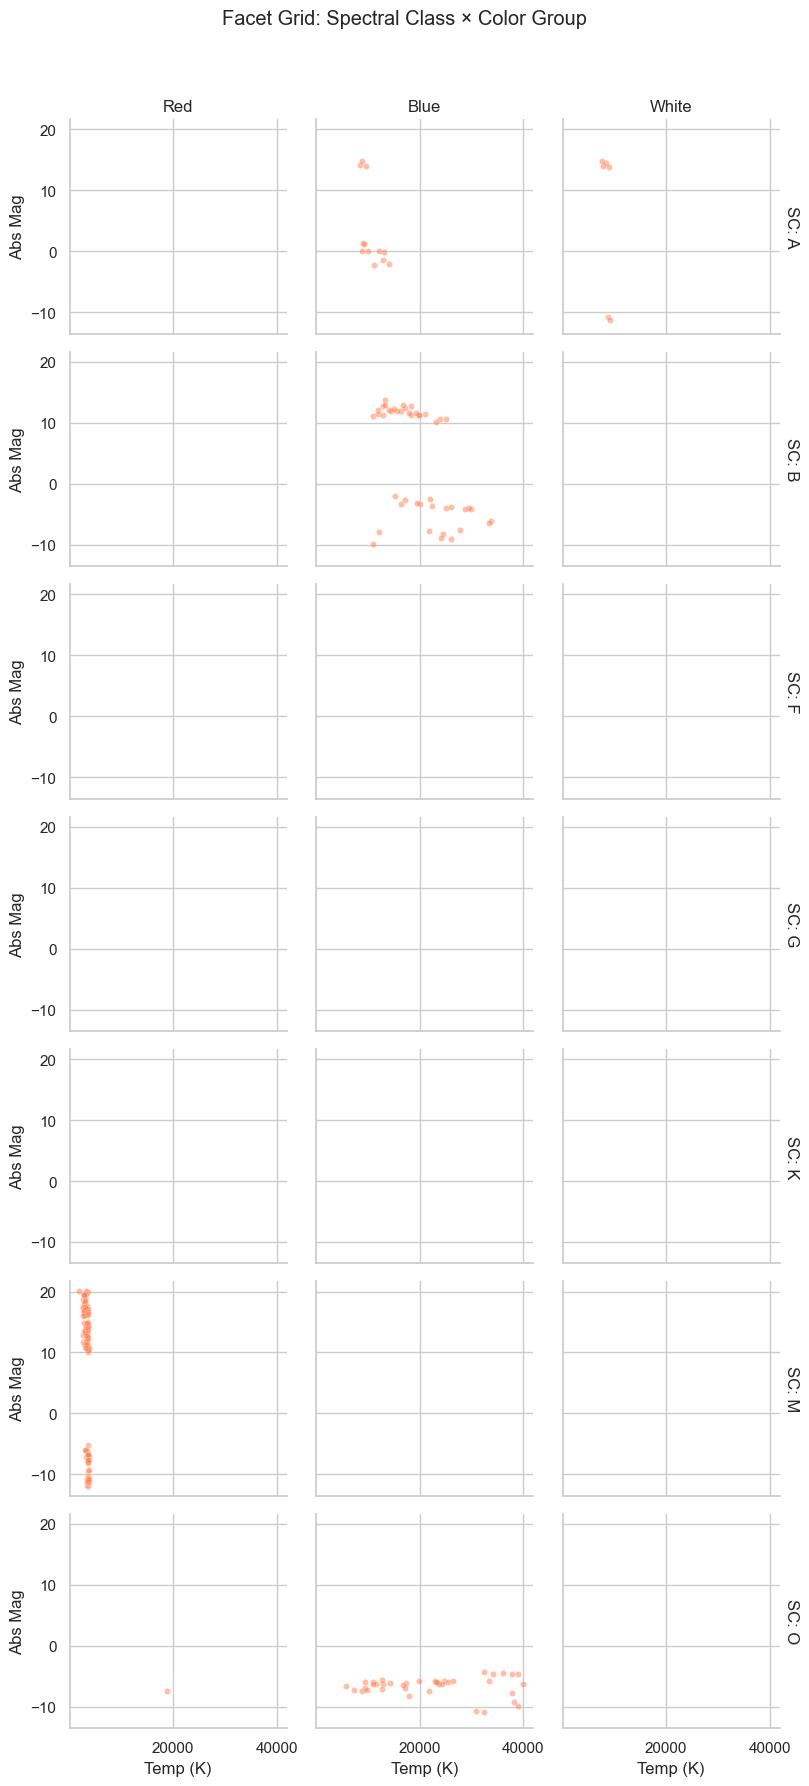

In [42]:
df_fg = df_clean[df_clean['Color_Group'].isin(['Red','Blue','White']) &
                 df_clean['Spectral Class'].astype(str).isin(['M','B','A','O'])].copy()
g = sns.FacetGrid(df_fg, row='Spectral Class', col='Color_Group',
                  height=2.5, aspect=1.1, margin_titles=True)
g.map_dataframe(sns.scatterplot, x='Temperature (K)', y='Abs_Magnitude',
                alpha=0.5, s=20, color='coral')
g.set_titles(row_template='SC: {row_name}', col_template='{col_name}')
g.set_axis_labels('Temp (K)', 'Abs Mag')
g.figure.suptitle('Facet Grid: Spectral Class × Color Group', y=1.02)
plt.tight_layout(); plt.show()


### Pairs Plot

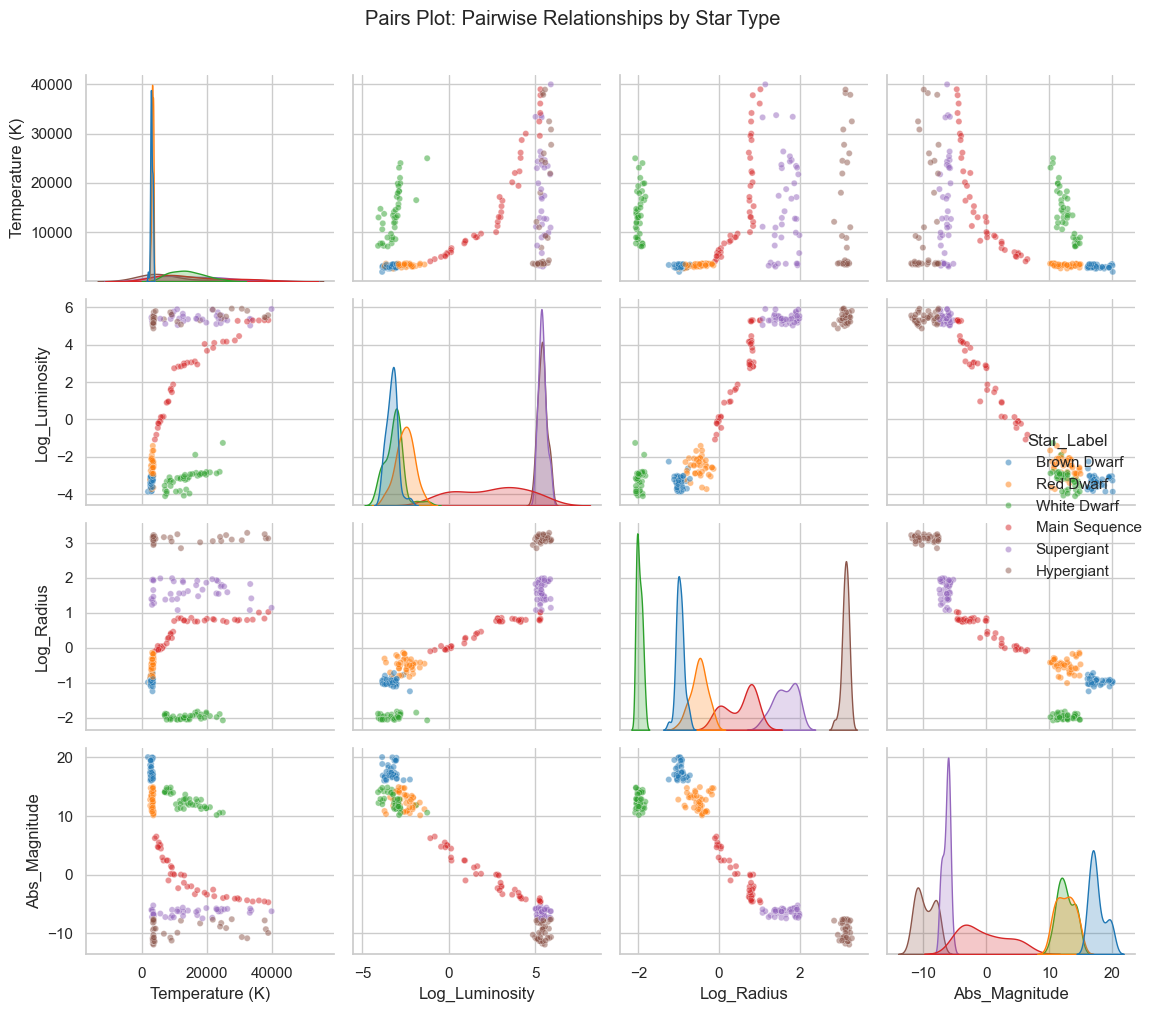

In [43]:
g = sns.pairplot(df_clean[['Temperature (K)','Log_Luminosity','Log_Radius',
                             'Abs_Magnitude','Star_Label']],
                 hue='Star_Label', palette='tab10',
                 plot_kws={'alpha':0.5,'s':20}, diag_kind='kde')
g.figure.suptitle('Pairs Plot: Pairwise Relationships by Star Type', y=1.01)
plt.tight_layout(); plt.show()


### Parallel Coordinates Plot

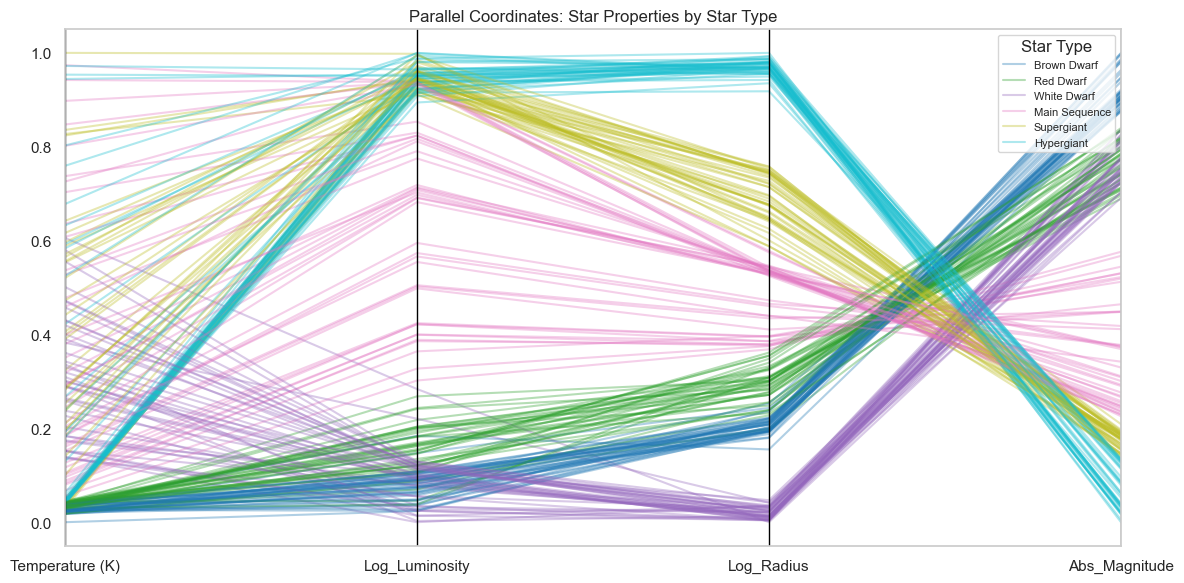

In [44]:
cols_pc = ['Temperature (K)','Log_Luminosity','Log_Radius','Abs_Magnitude','Star_Label']
df_pc = df_clean[cols_pc].copy()
for c in cols_pc[:-1]:
    df_pc[c] = (df_pc[c]-df_pc[c].min())/(df_pc[c].max()-df_pc[c].min())

fig, ax = plt.subplots(figsize=(12, 6))
parallel_coordinates(df_pc, 'Star_Label', ax=ax, colormap='tab10', alpha=0.35)
ax.set_title('Parallel Coordinates: Star Properties by Star Type')
ax.legend(title='Star Type', loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()


## 7. Statistical Analysis

### Pearson & Spearman Correlation + Scatter with Regression Line

Pearson  r = 0.4411  p = 7.53e-13
Spearman r = 0.4789  p = 3.68e-15


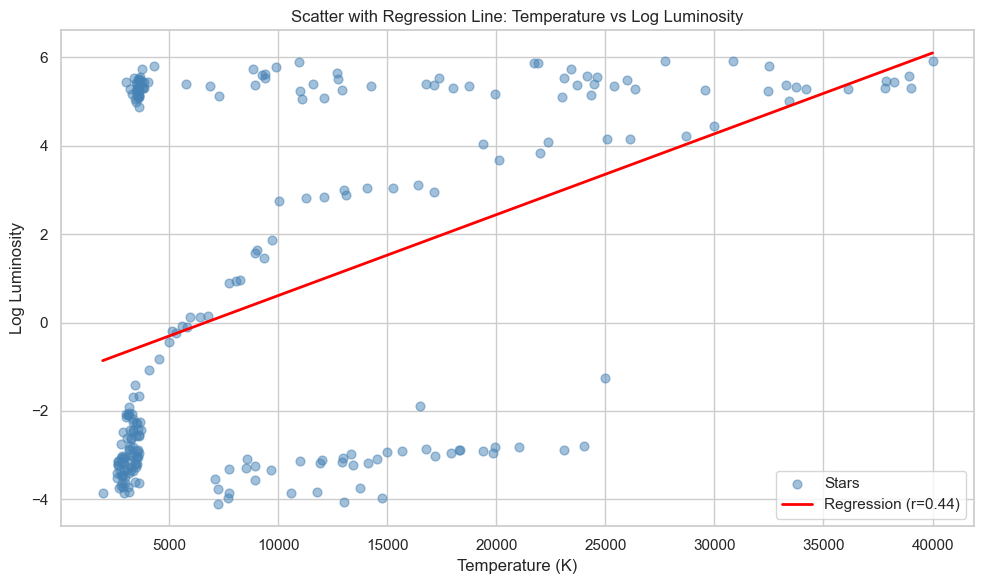

In [45]:
x = df_clean['Temperature (K)'].astype(float)
y = df_clean['Log_Luminosity'].astype(float)
pr, pp = pearsonr(x, y)
sr, sp = spearmanr(x, y)
print(f"Pearson  r = {pr:.4f}  p = {pp:.2e}")
print(f"Spearman r = {sr:.4f}  p = {sp:.2e}")

m, b = np.polyfit(x, y, 1)
xline = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, color='steelblue', alpha=0.5, s=40, label='Stars')
ax.plot(xline, m*xline+b, color='red', lw=2, label=f'Regression (r={pr:.2f})')
ax.set_title('Scatter with Regression Line: Temperature vs Log Luminosity')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity')
ax.legend(); plt.tight_layout(); plt.show()


### Grouped Statistics – Temperature by Star Type

In [46]:
grp = df_clean.groupby('Star_Label')['Temperature (K)'].agg(['mean','median','std']).round(2)
grp.columns = ['Mean','Median','Std Dev']
print("Temperature statistics aggregated by Star Type:")
print(grp)


Temperature statistics aggregated by Star Type:
                   Mean   Median   Std Dev
Star_Label                                
Brown Dwarf     2997.95   2935.0    332.28
Hypergiant     11405.70   3766.0  11816.99
Main Sequence  16018.00  12560.5  10661.23
Red Dwarf       3283.82   3314.0    269.64
Supergiant     15347.85  12821.0  10086.78
White Dwarf    13931.45  13380.0   4957.66


### Side-by-Side Box Plot + Violin Plot

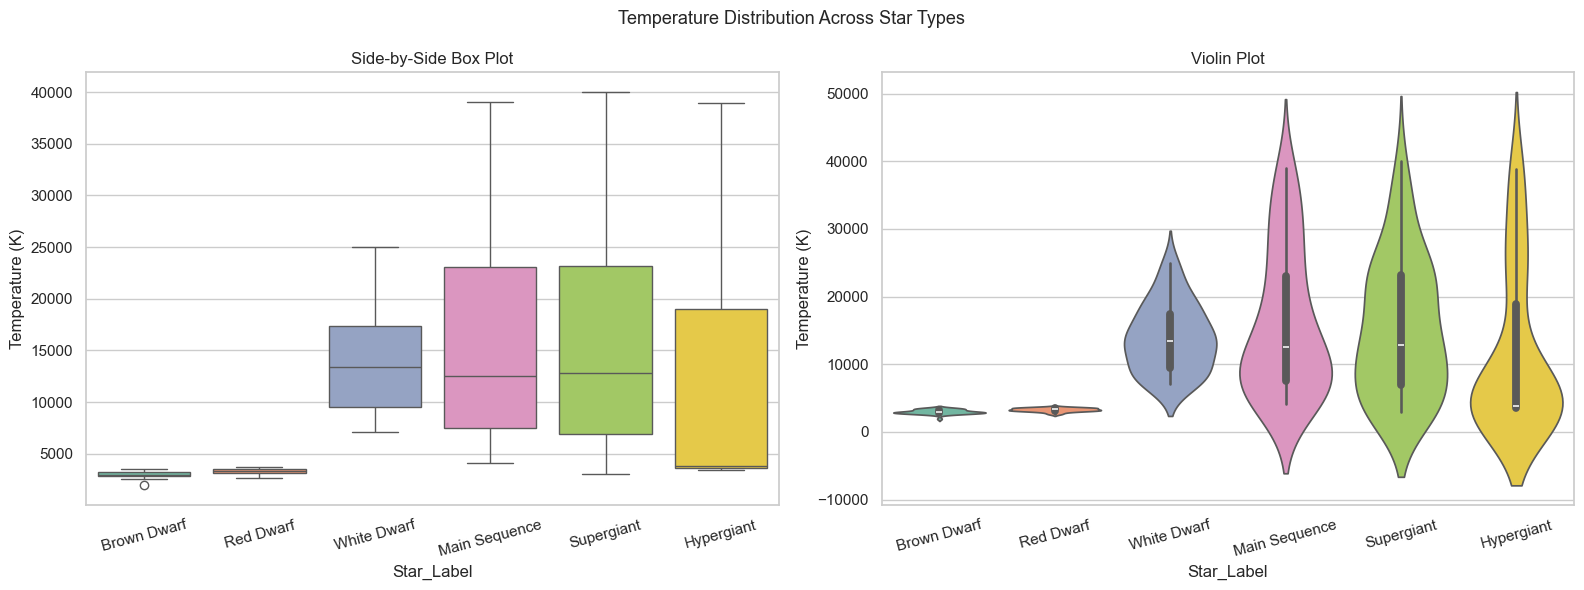

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df_clean,    x='Star_Label', y='Temperature (K)', palette='Set2', ax=axes[0])
axes[0].set_title('Side-by-Side Box Plot'); axes[0].tick_params(axis='x', rotation=15)

sns.violinplot(data=df_clean, x='Star_Label', y='Temperature (K)', palette='Set2', ax=axes[1])
axes[1].set_title('Violin Plot'); axes[1].tick_params(axis='x', rotation=15)
plt.suptitle('Temperature Distribution Across Star Types', fontsize=13)
plt.tight_layout(); plt.show()


### Faceted Box Plot + Grouped Bar with Error Bars (Two Categorical × One Numerical)

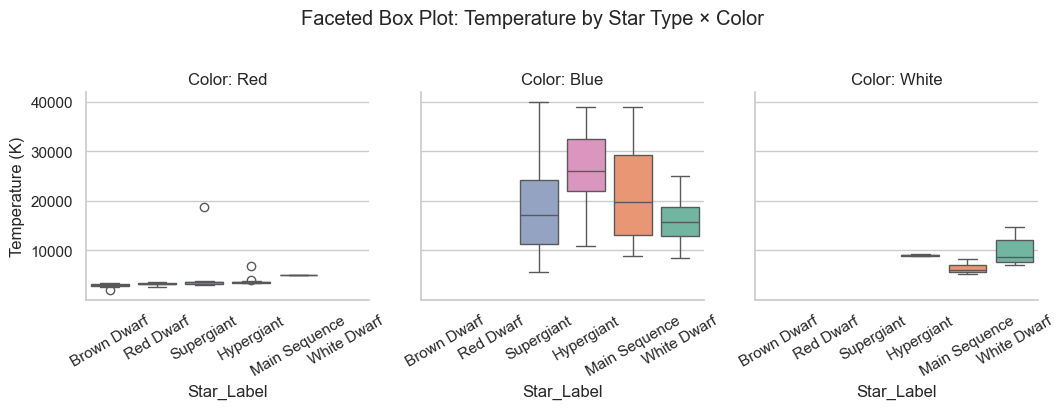

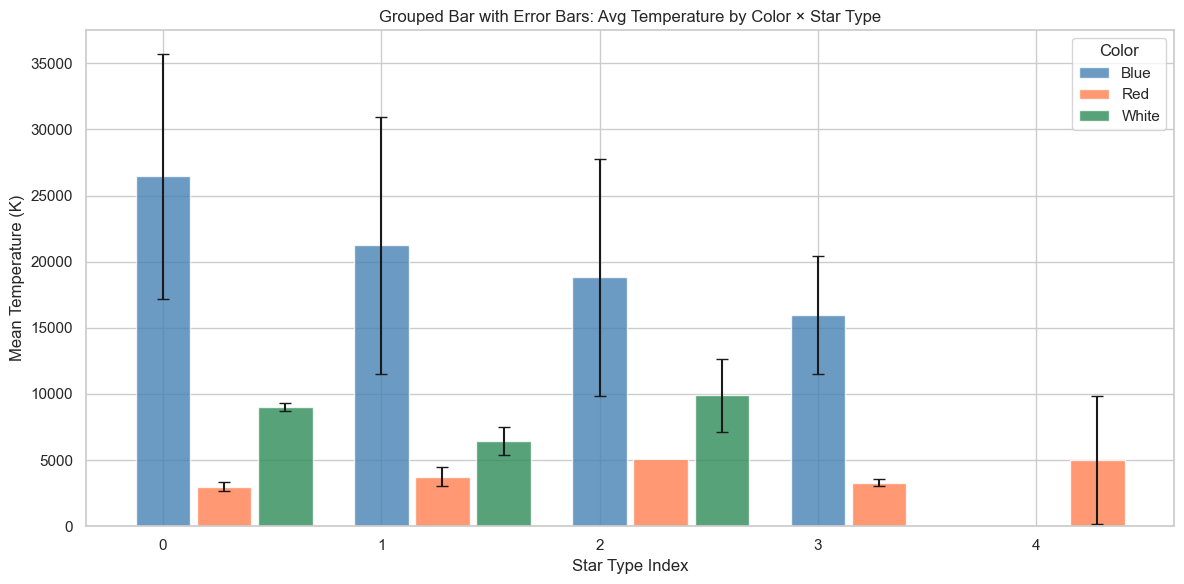

In [48]:
df_sub = df_clean[df_clean['Color_Group'].isin(['Red','Blue','White'])]

g = sns.FacetGrid(df_sub, col='Color_Group', height=4, aspect=0.9)
g.map_dataframe(sns.boxplot, x='Star_Label', y='Temperature (K)', palette='Set2')
g.set_xticklabels(rotation=30)
g.set_titles(col_template='Color: {col_name}')
g.figure.suptitle('Faceted Box Plot: Temperature by Star Type × Color', y=1.02)
plt.tight_layout(); plt.show()

err = df_sub.groupby(['Color_Group','Star_Label'])['Temperature (K)'].agg(['mean','std']).reset_index()
err.columns = ['Color','Label','Mean','Std']
fig, ax = plt.subplots(figsize=(12, 6))
colors3 = ['steelblue','coral','seagreen']
for i, (col, grp) in enumerate(err.groupby('Color')):
    xp = np.arange(len(grp)) + i*0.28
    ax.bar(xp, grp['Mean'], width=0.25, label=col, color=colors3[i],
           alpha=0.8, yerr=grp['Std'], capsize=4)
ax.set_title('Grouped Bar with Error Bars: Avg Temperature by Color × Star Type')
ax.set_xlabel('Star Type Index'); ax.set_ylabel('Mean Temperature (K)')
ax.legend(title='Color'); plt.tight_layout(); plt.show()


### Scatter Colored by Category + Per-Category Correlation

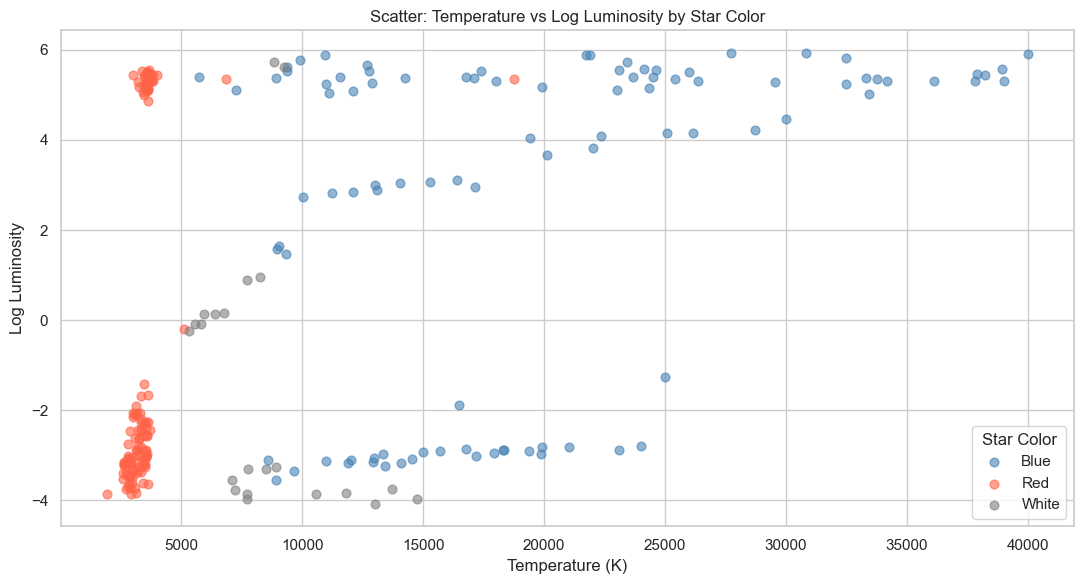

Per-category Pearson Correlation (Temperature vs Log Luminosity):
  Blue: r = 0.3651  (n=96)
  Red: r = 0.3025  (n=114)
  White: r = -0.3508  (n=22)


In [49]:
palette3 = {'Red':'tomato','Blue':'steelblue','White':'grey'}
fig, ax = plt.subplots(figsize=(11, 6))
for color, grp in df_sub.groupby('Color_Group'):
    ax.scatter(grp['Temperature (K)'], grp['Log_Luminosity'],
               label=color, color=palette3.get(color,'black'), alpha=0.6, s=40)
ax.set_title('Scatter: Temperature vs Log Luminosity by Star Color')
ax.set_xlabel('Temperature (K)'); ax.set_ylabel('Log Luminosity')
ax.legend(title='Star Color'); plt.tight_layout(); plt.show()

print("Per-category Pearson Correlation (Temperature vs Log Luminosity):")
for color, grp in df_sub.groupby('Color_Group'):
    if len(grp) > 3:
        r, _ = pearsonr(grp['Temperature (K)'], grp['Log_Luminosity'])
        print(f"  {color}: r = {r:.4f}  (n={len(grp)})")


### Full Correlation Matrix Heatmap

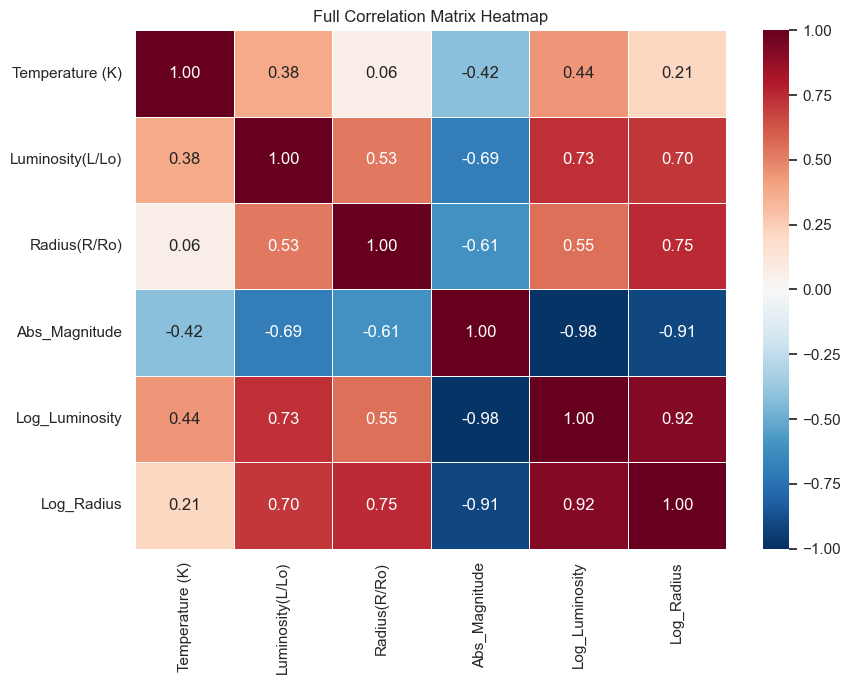

In [50]:
corr2 = df_clean[num_cols_h].astype(float).corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr2, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Full Correlation Matrix Heatmap')
plt.tight_layout(); plt.show()


### Pairs Plot / Scatterplot Matrix

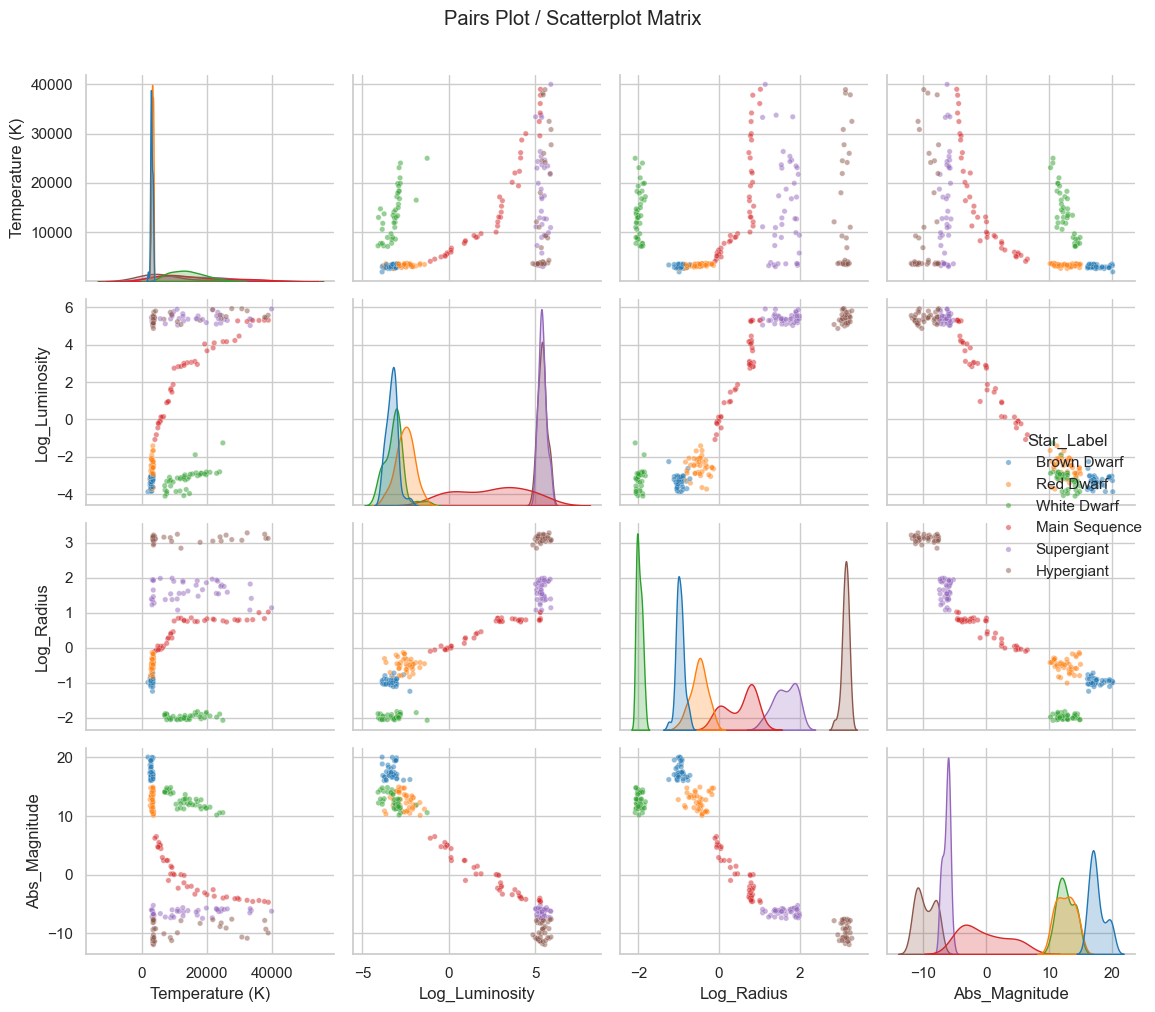

In [51]:
g = sns.pairplot(df_clean[['Temperature (K)','Log_Luminosity','Log_Radius',
                             'Abs_Magnitude','Star_Label']],
                 hue='Star_Label', palette='tab10',
                 plot_kws={'alpha':0.5,'s':15}, diag_kind='kde')
g.figure.suptitle('Pairs Plot / Scatterplot Matrix', y=1.01)
plt.tight_layout(); plt.show()


## 8. Time Series Analysis

Using the classic **AirPassengers** dataset (1949–1960, 144 monthly observations).

In [52]:
air_raw = [112,118,132,129,121,135,148,148,136,119,104,118,
           115,126,141,135,125,149,170,170,158,133,114,140,
           145,150,178,163,172,178,199,199,184,162,146,166,
           171,180,193,181,183,218,230,242,209,191,172,194,
           196,196,236,235,229,243,264,272,237,211,180,201,
           204,188,235,227,234,264,302,293,259,229,203,229,
           242,233,267,269,270,315,364,347,312,274,237,278,
           284,277,317,313,318,374,413,405,355,306,271,306,
           315,301,356,348,355,422,465,467,404,347,305,336,
           340,318,362,348,363,435,491,505,404,359,310,337,
           360,342,406,396,420,472,548,559,463,407,362,405,
           417,391,419,461,472,535,622,606,508,461,390,432]

idx = pd.date_range('1949-01', periods=144, freq='ME')
ts  = pd.Series(air_raw, index=idx, name='Passengers')

print(f"Start: {ts.index[0].date()}   End: {ts.index[-1].date()}")
print(f"Frequency: Monthly   Length: {len(ts)} observations")
print(f"Class: {type(ts).__name__}")
print("First 5:", ts.head(5).values, "  Last 5:", ts.tail(5).values)


Start: 1949-01-31   End: 1960-12-31
Frequency: Monthly   Length: 144 observations
Class: Series
First 5: [112 118 132 129 121]   Last 5: [606 508 461 390 432]


### Monthly Passenger Trend

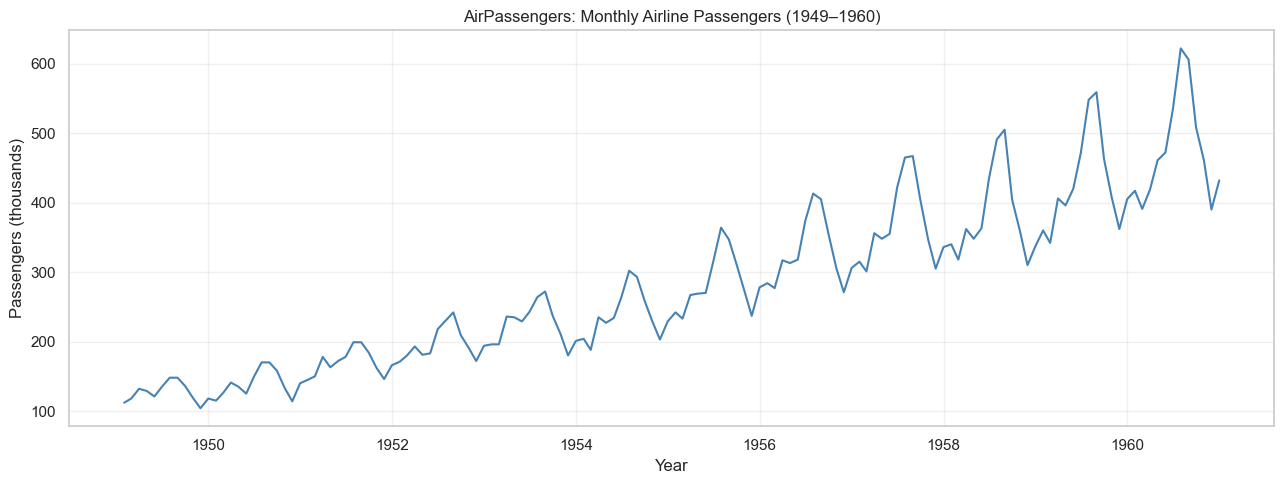

In [53]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(ts.index, ts.values, color='steelblue', lw=1.5)
ax.set_title('AirPassengers: Monthly Airline Passengers (1949–1960)')
ax.set_xlabel('Year'); ax.set_ylabel('Passengers (thousands)')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


### Decomposition – Trend, Seasonal, Residual Components

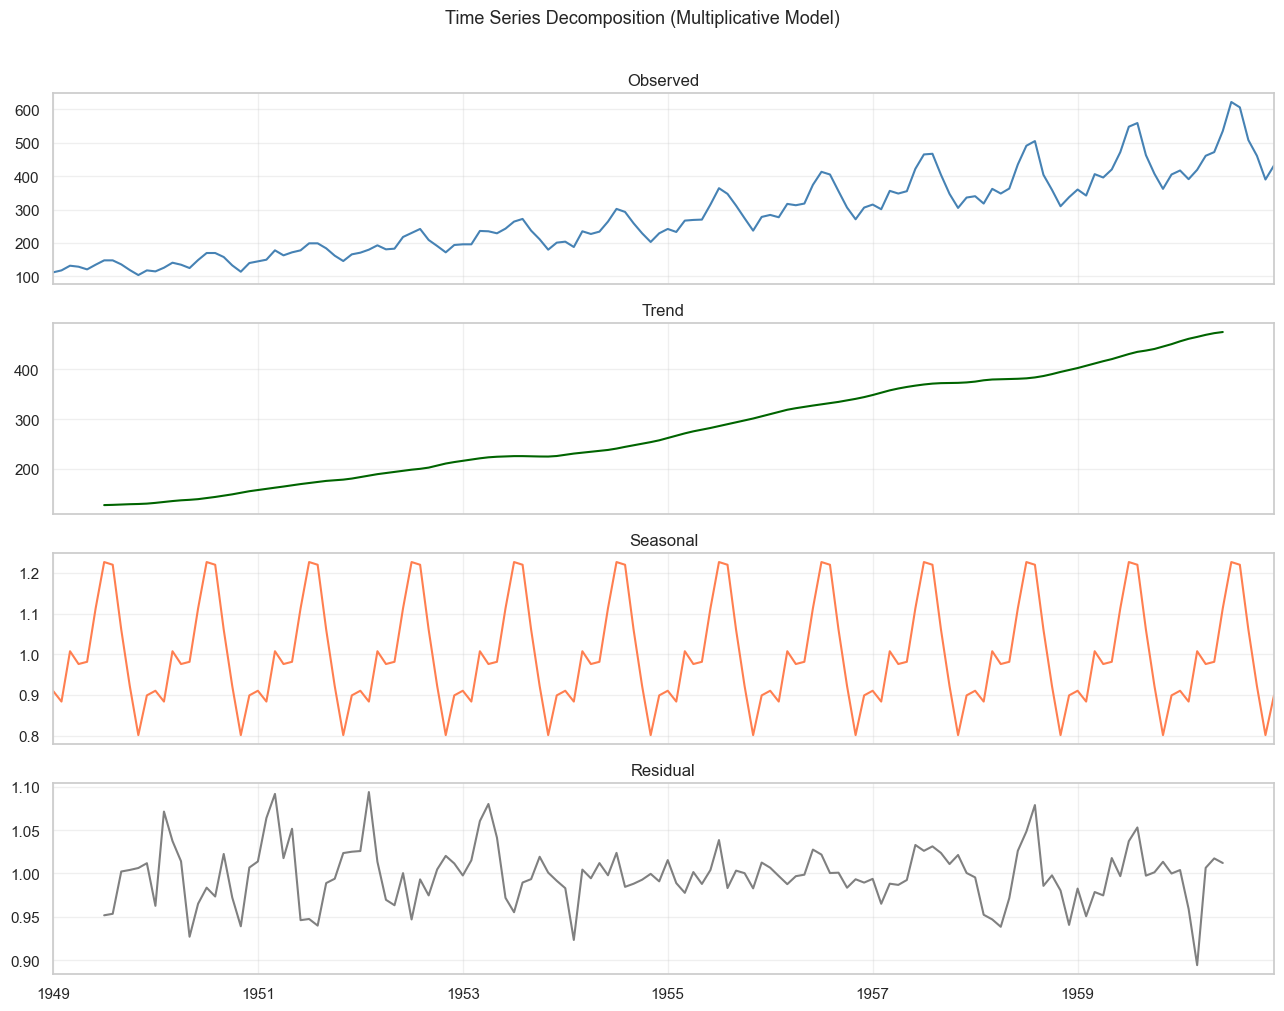

In [54]:
dec = seasonal_decompose(ts, model='multiplicative', period=12)
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
for ax, data, title, c in zip(axes,
        [dec.observed, dec.trend, dec.seasonal, dec.resid],
        ['Observed','Trend','Seasonal','Residual'],
        ['steelblue','darkgreen','coral','grey']):
    data.plot(ax=ax, color=c); ax.set_title(title); ax.grid(alpha=0.3)
plt.suptitle('Time Series Decomposition (Multiplicative Model)', fontsize=13, y=1.01)
plt.tight_layout(); plt.show()


### ACF and PACF

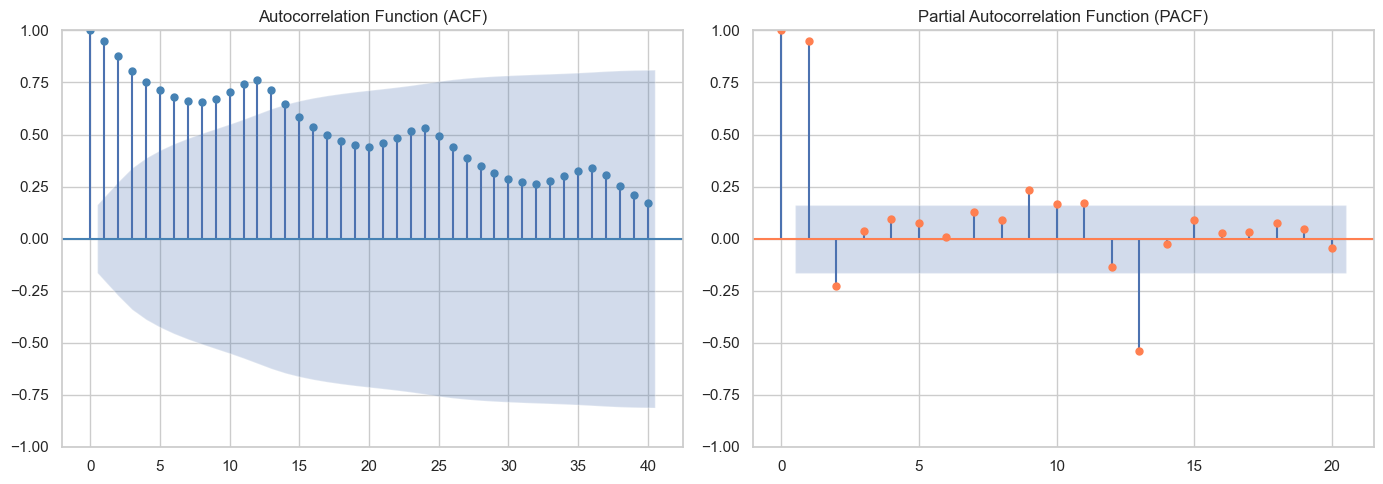

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(ts,  lags=40, ax=axes[0], color='steelblue'); axes[0].set_title('Autocorrelation Function (ACF)')
plot_pacf(ts, lags=20, ax=axes[1], color='coral', method='ywm'); axes[1].set_title('Partial Autocorrelation Function (PACF)')
plt.tight_layout(); plt.show()


### Fit SARIMA Model & Summary

In [56]:
log_ts = np.log(ts)
model  = SARIMAX(log_ts, order=(2,1,2), seasonal_order=(1,1,1,12),
                 enforce_stationarity=False, enforce_invertibility=False)
fit = model.fit(disp=False)
print(fit.summary())


                                      SARIMAX Results                                       
Dep. Variable:                           Passengers   No. Observations:                  144
Model:             SARIMAX(2, 1, 2)x(1, 1, [1], 12)   Log Likelihood                 217.889
Date:                              Sun, 18 Oct 2026   AIC                           -421.778
Time:                                      22:19:52   BIC                           -402.503
Sample:                                  01-31-1949   HQIC                          -413.954
                                       - 12-31-1960                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.6736      0.251     -2.680      0.007      -1.166      -0.181
ar.L2          0.08

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


### Forecast Next 12 Months

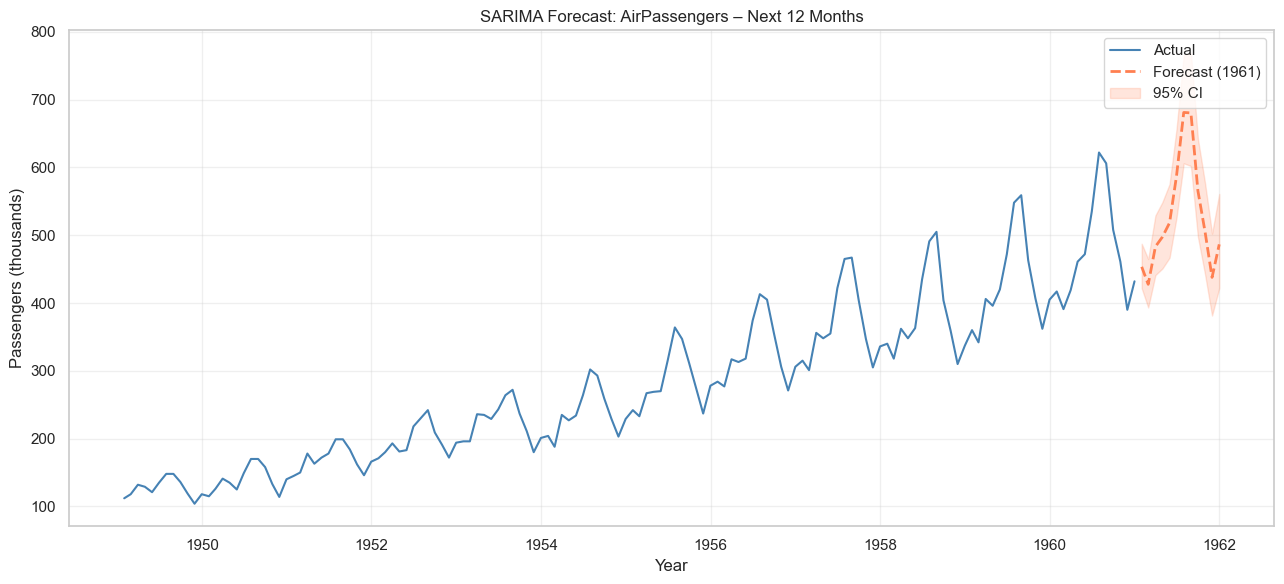


Forecasted values for 1961:
  1961-01: 453
  1961-02: 428
  1961-03: 483
  1961-04: 497
  1961-05: 518
  1961-06: 588
  1961-07: 681
  1961-08: 680
  1961-09: 566
  1961-10: 505
  1961-11: 438
  1961-12: 487


In [57]:
fcast  = fit.get_forecast(steps=12)
f_mean = np.exp(fcast.predicted_mean)
f_ci   = np.exp(fcast.conf_int())
f_idx  = pd.date_range('1961-01', periods=12, freq='ME')

fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(ts.index, ts.values, label='Actual', color='steelblue', lw=1.5)
ax.plot(f_idx, f_mean.values, '--', color='coral', lw=2, label='Forecast (1961)')
ax.fill_between(f_idx, f_ci.iloc[:,0].values, f_ci.iloc[:,1].values,
                color='coral', alpha=0.2, label='95% CI')
ax.set_title('SARIMA Forecast: AirPassengers – Next 12 Months')
ax.set_xlabel('Year'); ax.set_ylabel('Passengers (thousands)')
ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

print("\nForecasted values for 1961:")
for d, v in zip(f_idx, f_mean.values):
    print(f"  {d.strftime('%Y-%m')}: {v:.0f}")


## 9. Clustering Analysis

### Prepare & Standardise Data

In [58]:
feat_cols = ['Temperature (K)','Luminosity(L/Lo)','Radius(R/Ro)','Abs_Magnitude']
df_cl = df_clean[feat_cols].astype(float).dropna()
print(f"Clustering data shape: {df_cl.shape}")
print("Class distribution:")
print(df_clean.loc[df_cl.index,'Star type'].value_counts().sort_index())

scaler_cl = StandardScaler()
X_scaled  = scaler_cl.fit_transform(df_cl)
print(f"\nMean after scaling (≈0): {X_scaled.mean(axis=0).round(3)}")
print(f"Std  after scaling (≈1): {X_scaled.std(axis=0).round(3)}")


Clustering data shape: (240, 4)
Class distribution:
Star type
0    40
1    40
2    40
3    40
4    40
5    40
Name: count, dtype: int64

Mean after scaling (≈0): [-0.  0. -0. -0.]
Std  after scaling (≈1): [1. 1. 1. 1.]


### K-Means Clustering (k=2) – Centres & Results

In [59]:
km2 = KMeans(n_clusters=2, random_state=42, n_init=10)
km2.fit(X_scaled)
print("K=2  |  Cluster Sizes:", np.bincount(km2.labels_))
print("WCSS:", round(km2.inertia_, 2))
print("\nCluster Centres:")
print(pd.DataFrame(km2.cluster_centers_, columns=feat_cols).round(3))


K=2  |  Cluster Sizes: [ 91 149]
WCSS: 509.33

Cluster Centres:
   Temperature (K)  Luminosity(L/Lo)  Radius(R/Ro)  Abs_Magnitude
0            0.526             0.973         0.750         -1.136
1           -0.321            -0.594        -0.458          0.694


### Elbow Plot – WCSS for k=1 to 10

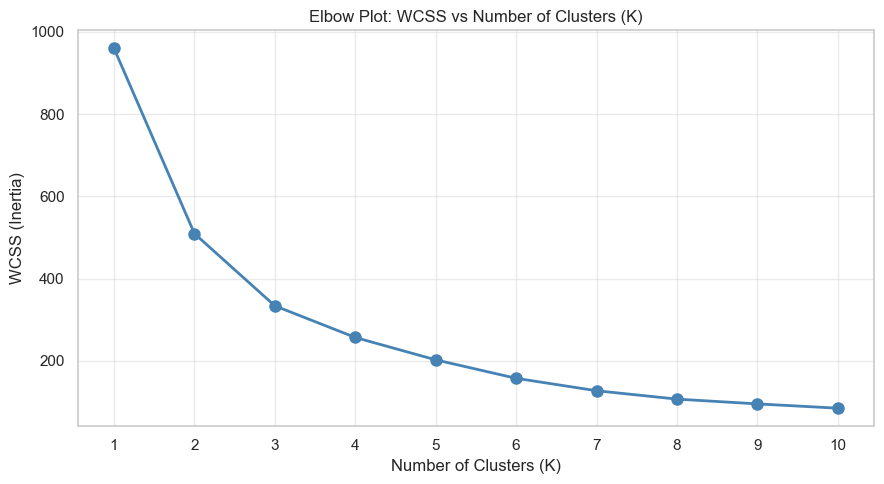

  K=1: 960.00
  K=2: 509.33
  K=3: 333.54
  K=4: 256.56
  K=5: 202.10
  K=6: 157.16
  K=7: 126.93
  K=8: 106.54
  K=9: 94.90
  K=10: 84.47


In [60]:
wcss = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_
        for k in range(1, 11)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1,11), wcss, 'o-', color='steelblue', lw=2, ms=8)
ax.set_title('Elbow Plot: WCSS vs Number of Clusters (K)')
ax.set_xlabel('Number of Clusters (K)'); ax.set_ylabel('WCSS (Inertia)')
ax.set_xticks(range(1,11)); ax.grid(alpha=0.4)
plt.tight_layout(); plt.show()

for k, w in enumerate(wcss, 1):
    print(f"  K={k}: {w:.2f}")


### K-Means with Optimal K=6 (Elbow Recommendation)

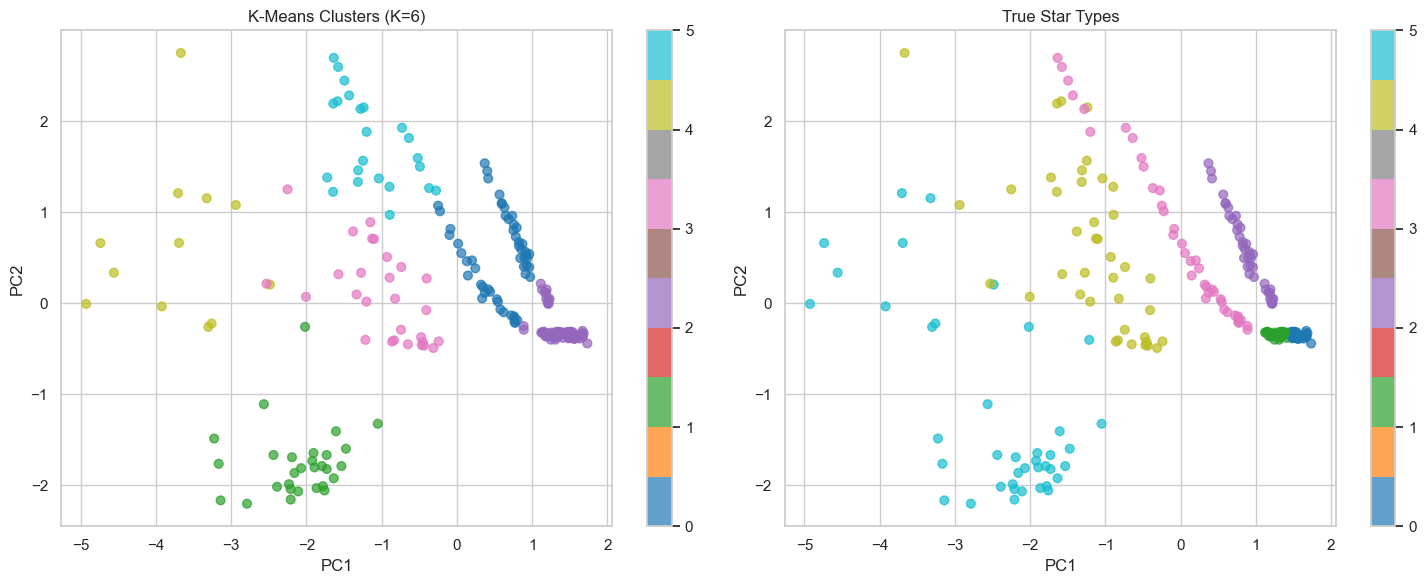

K=6  Cluster Sizes: [55 29 93 28 12 23]  WCSS: 157.16


In [61]:
km6 = KMeans(n_clusters=6, random_state=42, n_init=10)
km6.fit(X_scaled)

pca2    = PCA(n_components=2)
X2d     = pca2.fit_transform(X_scaled)
true_lbl = df_clean.loc[df_cl.index,'Star type'].astype(int).values

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, lbl, title in zip(axes, [km6.labels_, true_lbl],
                           ['K-Means Clusters (K=6)','True Star Types']):
    sc = ax.scatter(X2d[:,0], X2d[:,1], c=lbl, cmap='tab10', alpha=0.7, s=40)
    plt.colorbar(sc, ax=ax)
    ax.set_title(title); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout(); plt.show()
print(f"K=6  Cluster Sizes: {np.bincount(km6.labels_)}  WCSS: {km6.inertia_:.2f}")


### Hierarchical Clustering – Dendrogram (Ward's Method)

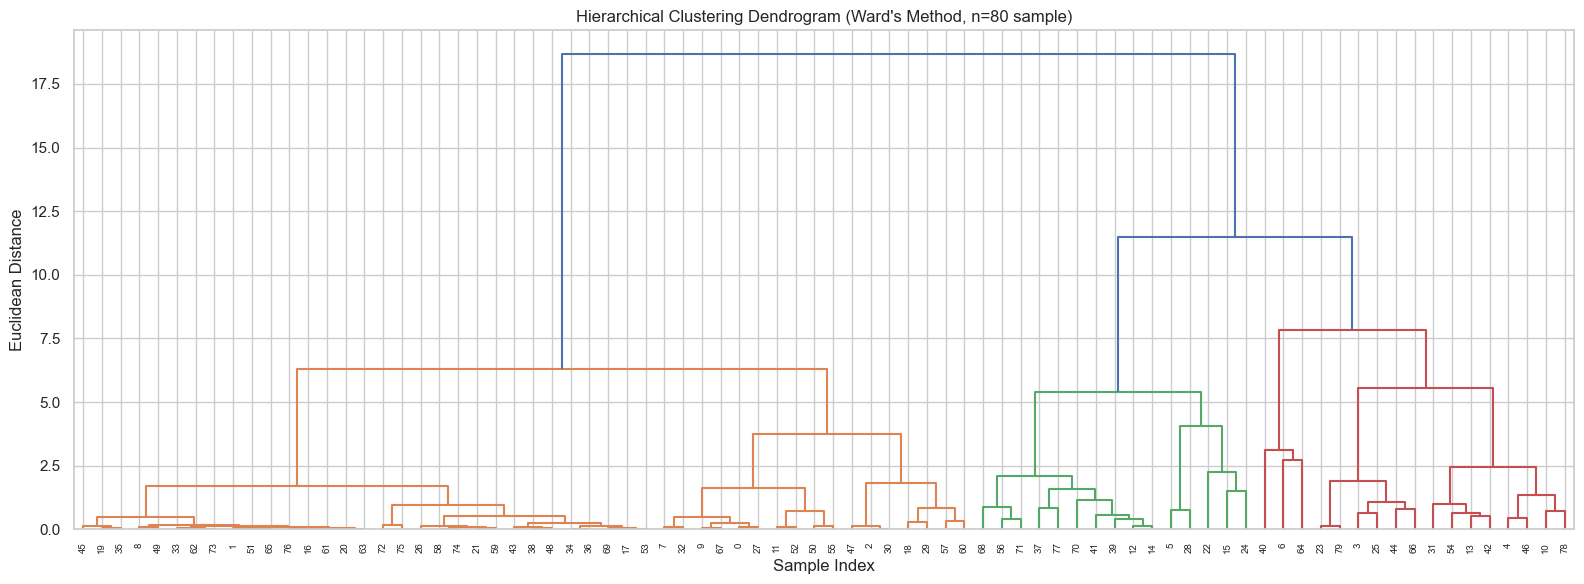

In [62]:
rng   = np.random.RandomState(42)
idx80 = rng.choice(len(X_scaled), 80, replace=False)
Z     = linkage(X_scaled[idx80], method='ward')

fig, ax = plt.subplots(figsize=(16, 6))
dendrogram(Z, ax=ax, leaf_rotation=90, leaf_font_size=7, color_threshold=10)
ax.set_title("Hierarchical Clustering Dendrogram (Ward's Method, n=80 sample)")
ax.set_xlabel('Sample Index'); ax.set_ylabel('Euclidean Distance')
plt.tight_layout(); plt.show()


### Cut Tree into 3 Clusters

In [63]:
labels3 = fcluster(Z, t=3, criterion='maxclust')
print("Hierarchical Clustering – 3 Clusters:")
for c, n in enumerate(np.bincount(labels3)[1:], 1):
    print(f"  Cluster {c}: {n} samples")


Hierarchical Clustering – 3 Clusters:
  Cluster 1: 48 samples
  Cluster 2: 15 samples
  Cluster 3: 17 samples


## 10. Principal Component Analysis (PCA)

**Registration Number: 23BDS0176**

### Scale Data for PCA

In [64]:
pca_cols = ['Temperature (K)','Luminosity(L/Lo)','Radius(R/Ro)','Abs_Magnitude']
df_pca_raw = df_clean[pca_cols].astype(float).dropna()
print(f"Dataset: {df_pca_raw.shape[0]} rows × {df_pca_raw.shape[1]} columns")

scaler_p  = StandardScaler()
data_scaled = scaler_p.fit_transform(df_pca_raw)
print("Data scaled (data_scaled). Shape:", data_scaled.shape)


Dataset: 240 rows × 4 columns
Data scaled (data_scaled). Shape: (240, 4)


### Perform PCA & Print Summary

In [65]:
pca_full    = PCA()
pca_full.fit(data_scaled)
scores_full = pca_full.transform(data_scaled)

exp_var = pca_full.explained_variance_ratio_ * 100
cum_var = np.cumsum(exp_var)
n_pc    = len(exp_var)

print(f"{'PC':<6}{'Eigenvalue':>12}{'% Var':>10}{'Cum %':>10}")
print('-'*40)
for i,(ev,v,c) in enumerate(zip(pca_full.explained_variance_, exp_var, cum_var)):
    print(f"PC{i+1:<4}{ev:>12.4f}{v:>9.2f}%{c:>9.2f}%")


PC      Eigenvalue     % Var     Cum %
----------------------------------------
PC1         2.4199    60.24%    60.24%
PC2         0.9440    23.50%    83.75%
PC3         0.3787     9.43%    93.17%
PC4         0.2742     6.83%   100.00%


### Scree Plot (y-axis 0–60)

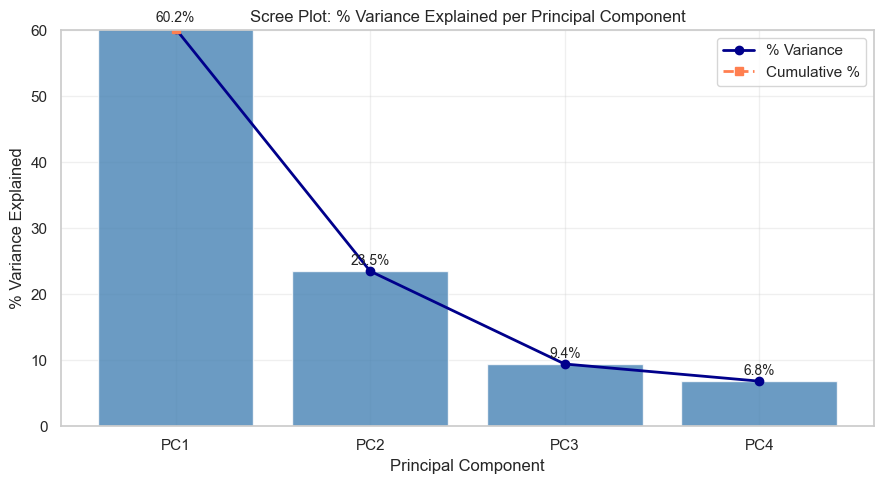

In [66]:
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(range(1, n_pc+1), exp_var, color='steelblue', edgecolor='white', alpha=0.8)
ax.plot(range(1, n_pc+1), exp_var,  'o-', color='darkblue', lw=2, label='% Variance')
ax.plot(range(1, n_pc+1), cum_var, 's--', color='coral',    lw=2, label='Cumulative %')
for bar, v in zip(bars, exp_var):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+.5,
            f'{v:.1f}%', ha='center', va='bottom', fontsize=10)
ax.set_ylim(0, 60)
ax.set_title('Scree Plot: % Variance Explained per Principal Component')
ax.set_xlabel('Principal Component'); ax.set_ylabel('% Variance Explained')
ax.set_xticks(range(1, n_pc+1))
ax.set_xticklabels([f'PC{i}' for i in range(1, n_pc+1)])
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


### PCA Biplot (with non-overlapping labels)

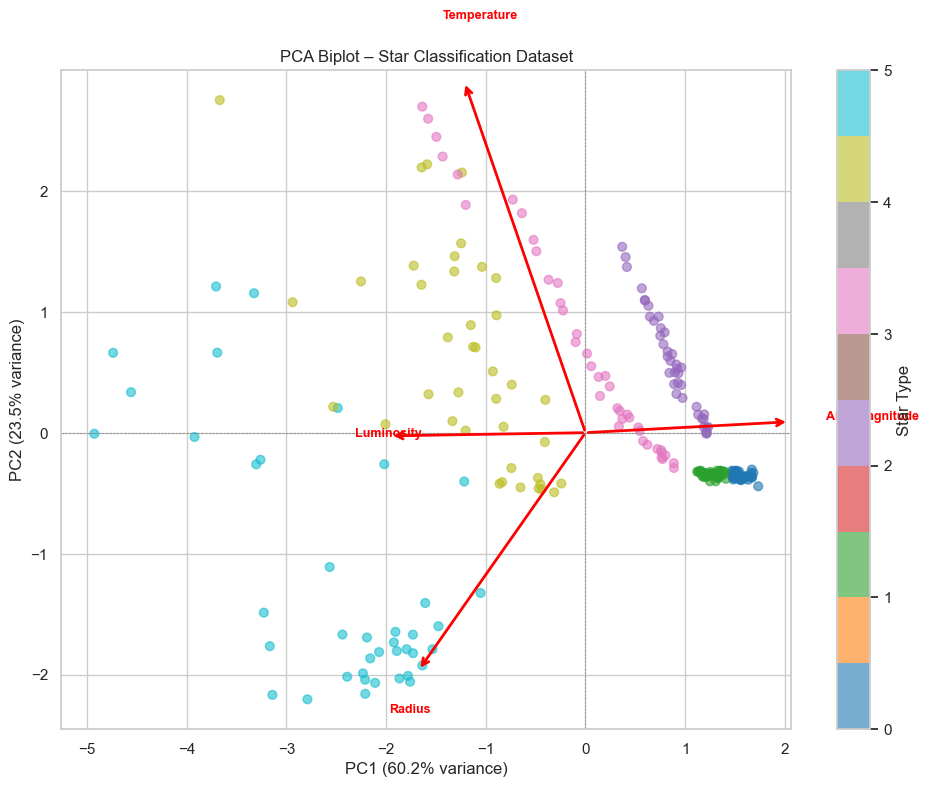

In [67]:
loadings    = pca_full.components_
star_colors = df_clean.loc[df_pca_raw.index,'Star type'].astype(int).values

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(scores_full[:,0], scores_full[:,1],
                c=star_colors, cmap='tab10', alpha=0.6, s=40)
plt.colorbar(sc, ax=ax, label='Star Type')

scale = 3.5
for i, feat in enumerate(pca_cols):
    ax.annotate('', xy=(loadings[0,i]*scale, loadings[1,i]*scale),
                xytext=(0,0), arrowprops=dict(arrowstyle='->', color='red', lw=2))
    ax.text(loadings[0,i]*scale*1.18, loadings[1,i]*scale*1.18,
            feat.split('(')[0].strip(), color='red', fontsize=9, fontweight='bold')
ax.axhline(0,color='grey',lw=.5,ls='--'); ax.axvline(0,color='grey',lw=.5,ls='--')
ax.set_title('PCA Biplot – Star Classification Dataset')
ax.set_xlabel(f'PC1 ({exp_var[0]:.1f}% variance)')
ax.set_ylabel(f'PC2 ({exp_var[1]:.1f}% variance)')
plt.tight_layout(); plt.show()


### PCA Scores (first 6 rows)

In [68]:
pca_scores = pd.DataFrame(scores_full,
                           columns=[f'PC{i+1}' for i in range(n_pc)],
                           index=df_pca_raw.index)
print("PCA Scores (pca_scores) – First 6 rows:")
print(pca_scores.head(6).round(4))


PCA Scores (pca_scores) – First 6 rows:
      PC1     PC2     PC3     PC4
0  1.4728 -0.3546  0.1582  0.3158
1  1.5004 -0.3557  0.1627  0.3520
2  1.6330 -0.3889  0.1946  0.5015
3  1.5120 -0.3766  0.1721  0.3493
4  1.7324 -0.4430  0.2294  0.5883
5  1.5289 -0.3723  0.1731  0.3757


### PC1 vs PC2 Scatter – Reg No: 23BDS0176

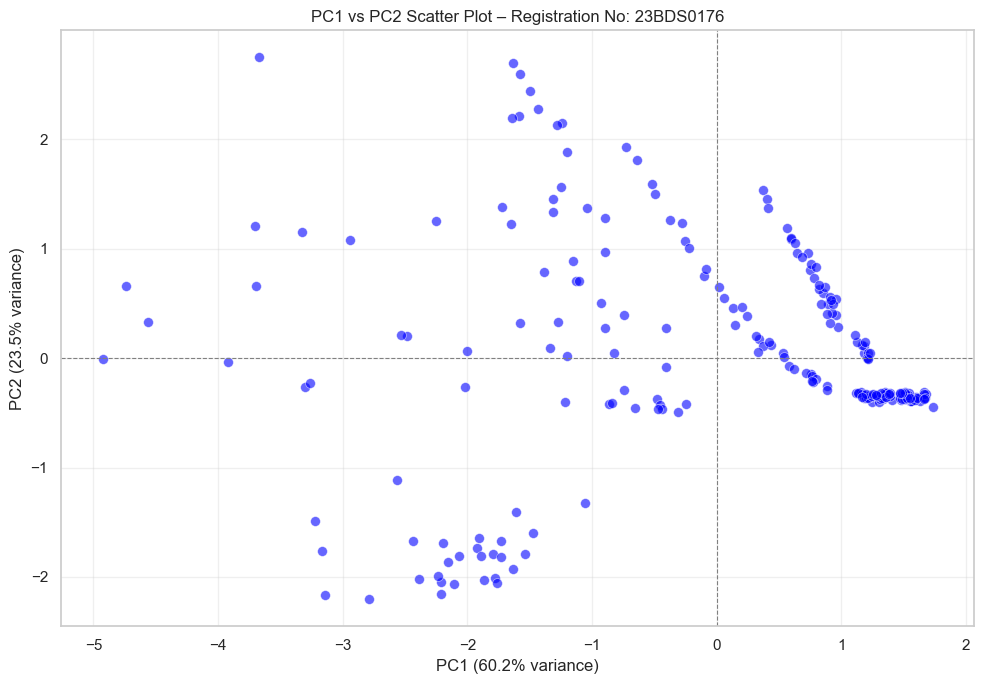

In [69]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(pca_scores['PC1'], pca_scores['PC2'],
           color='blue', marker='o', alpha=0.6, s=50,
           edgecolors='white', linewidths=0.5)
ax.set_title('PC1 vs PC2 Scatter Plot – Registration No: 23BDS0176')
ax.set_xlabel(f'PC1 ({exp_var[0]:.1f}% variance)')
ax.set_ylabel(f'PC2 ({exp_var[1]:.1f}% variance)')
ax.axhline(0, color='grey', lw=.8, ls='--')
ax.axvline(0, color='grey', lw=.8, ls='--')
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


---
## Summary

| Section | Topics Covered |
|---|---|
| Dataset Loading & Exploration | Import, head/tail, shape, dtypes, summary, missing values |
| Data Cleaning | Mean/Median/Mode/ffill/bfill imputation, duplicates, type conversion, derived cols |
| Descriptive Statistics | Min, Max, Range, Variance, Std Dev, IQR, Skewness, Kurtosis |
| Univariate Analysis | Outliers (IQR), Histogram+KDE, Violin, Dot, Pie, Bar, Lollipop, Density, Facets |
| Bivariate Analysis | Contingency table, Stacked/Grouped bars, Scatter, Line, Heatmap, Box, Correlogram |
| Multivariate Analysis | 3/4-var Scatter, Bubble, Facet Wrap/Grid, Pairs Plot, Parallel Coordinates |
| Statistical Analysis | Pearson/Spearman correlation, Regression line, Grouped stats, Error Bars |
| Time Series | Decomposition, ACF/PACF, SARIMA, 12-month Forecast |
| Clustering | K-Means (Elbow), Hierarchical (Dendrogram, Ward's) |
| PCA | Scree Plot, Biplot, PC1 vs PC2 |

**Name:** P V S SRUTHI &nbsp;|&nbsp; **Reg No:** 23BDS0176 &nbsp;|&nbsp; **Course:** BCSE331P
